**Group Name:** 6

**Name:** Xinrui SHAN, Huibo LI 

**EIDs:** xinruis2, huiboli2



# CS5495 - Course Project (2025A)

## 0. Research Goal

Our project aims to investigate how different XAI methods can explain predictions of a pretrained **BERT** model (textattack/bert-base-uncased-SST-2) on the SST‑2 **sentiment classification task**. Specifically, we explore eight XAI methods: Integrated Gradients (IG), LIME‑Text, SHAP‑Text, Sufficiency & Comprehensiveness (Span Deletion/Insertion), Attention Rollout, Anchors‑Text, DiCE‑Text, and Activation/Path Patching. And the first five of them are in-class methods while others are out-class.

The research questions we explore are:
- Which input spans drive the model’s class predictions?
- Which layers are responsible for these predictions?
- How effective are counterfactual edits in testing controllability?

The following parts are our code and report.

## 1. Config

In [1]:
import torch
from dataclasses import dataclass

@dataclass
class Cfg:
    model_name: str = "textattack/bert-base-uncased-SST-2"  # fine-tuned BERT binary classifier
    device: str = "cuda:0" if torch.cuda.is_available() else "cpu"
    max_len: int = 128
    target_label: int = 1  # SST-2: 1=positive
    top_k: int = 5
    ig_steps: int = 32
    shap_max_evals: int = 500
    lime_num_samples: int = 1000
    layer_idx: int = 9  # for activation patching
    sample_text: str | None = None  # set a string here to override the default sample

cfg = Cfg()
cfg


Cfg(model_name='textattack/bert-base-uncased-SST-2', device='cuda:0', max_len=128, target_label=1, top_k=5, ig_steps=32, shap_max_evals=500, lime_num_samples=1000, layer_idx=9, sample_text=None)

## 2. Imports & Helpers

In [2]:

import os, json, math, random
from typing import List, Tuple, Dict, Optional
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt


_ALIBI_OK = True

from datasets import load_from_disk, load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoModelForMaskedLM,
    TextClassificationPipeline,
)

from captum.attr import IntegratedGradients
from lime.lime_text import LimeTextExplainer
import shap

# Optional: Anchors-Text
try:
    from alibi.explainers import AnchorText
    import spacy
    _ALIBI_OK = True
except Exception:
    _ALIBI_OK = False

def set_seed(s: int = 2025):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def load_bert(model_path, device="cpu"):
    tok = AutoTokenizer.from_pretrained(model_path, local_files_only=True)
    mdl = AutoModelForSequenceClassification.from_pretrained(model_path, local_files_only=True)
    pipe = TextClassificationPipeline(model=mdl, tokenizer=tok, device=0 if device=="cuda" else -1)
    return tok, mdl, pipe

def predict_proba(pipe: TextClassificationPipeline, texts: List[str]) -> np.ndarray:
    out = pipe(texts)
    return np.array([[d["score"] for d in sample] for sample in out], dtype=np.float32)

def predict_proba_single(pipe: TextClassificationPipeline, texts: str) -> np.ndarray:
    out = pipe(texts, return_all_scores=True)  # ensure scores for all classes are returned
    probs = []
    for sample in out:
        row = [d['score'] for d in sample]  # follow the score order returned by the pipeline
        probs.append(row)
    return np.array(probs, dtype=np.float32)




def get_label_names(model) -> List[str]:
    id2label = getattr(model.config, "id2label", None)
    if id2label:
        return [id2label[i] for i in range(len(id2label))]
    return [f"class_{i}" for i in range(model.config.num_labels)]

def ig_attributions(text: str, model, tokenizer, target: int, device: str, max_len: int, steps: int):
    # Why: running IG on embeddings is more robust to gradient saturation
    model.to(device).eval()
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=max_len)
    input_ids = enc["input_ids"].to(device)
    attention_mask = enc["attention_mask"].to(device)
    emb_layer = model.get_input_embeddings()
    def fwd(embeds): 
        return model(inputs_embeds=embeds, attention_mask=attention_mask).logits[:, target]
    baseline = torch.zeros_like(emb_layer(input_ids))
    ig = IntegratedGradients(fwd)
    attrs, _ = ig.attribute(inputs=emb_layer(input_ids), baselines=baseline, n_steps=steps, return_convergence_delta=True)
    token_attr = attrs.sum(-1).squeeze(0).detach().cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(input_ids[0])
    return tokens, token_attr

def sufficiency_comprehensiveness(text: str, token_attr: np.ndarray, tokens: List[str], pipe, k: int, cls_index: int, tokenizer, max_len: int):
    specials = {tokenizer.cls_token, tokenizer.sep_token, tokenizer.pad_token}
    valid = np.array([t not in specials for t in tokens])
    idx = np.argsort(-np.abs(token_attr * valid))[:k]

    base_prob = predict_proba_single(pipe, [text])[0][cls_index]
    words = tokenizer.convert_tokens_to_string(tokens).split()
    kept = " ".join([w for j, w in enumerate(words) if j in idx])
    removed = " ".join([w for j, w in enumerate(words) if j not in idx])

    suff = predict_proba_single(pipe, [kept])[0][cls_index]
    comp = base_prob - predict_proba_single(pipe, [removed])[0][cls_index]
    return {"baseline": float(base_prob), "sufficiency": float(suff), "comprehensiveness": float(comp)}, idx

def attention_rollout(text: str, model, tokenizer, device: str, max_len: int, residual_alpha: float = 1.0):
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=max_len).to(device)
    with torch.no_grad():
        out = model(**enc, output_attentions=True)
    atts = torch.stack(out.attentions, dim=0).mean(dim=2)  # L,B,T,T
    L,B,T,_ = atts.shape
    eye = torch.eye(T, device=atts.device).unsqueeze(0).unsqueeze(1).expand(L,B,T,T)
    a_hat = (atts + residual_alpha * eye) / (1.0 + residual_alpha)
    roll = a_hat[0]
    for l in range(1, L):
        roll = torch.bmm(a_hat[l], roll)
    tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
    return tokens, roll.squeeze(0).cpu().numpy()

def lime_explain(text: str, class_names: List[str], pipe, num_features: int, num_samples: int):
    pipe.model.to("cuda")
    pipe.device = torch.device("cuda")
    explainer = LimeTextExplainer(class_names=class_names)
    exp = explainer.explain_instance(text, classifier_fn=lambda xs: predict_proba_single(pipe, xs), num_features=num_features, num_samples=num_samples)
    return exp.as_list()

def shap_explain(texts: List[str], pipe, max_evals: int):
    masker = shap.maskers.Text()
    explainer = shap.Explainer(lambda x: predict_proba_single(pipe, list(x)), masker=masker, algorithm="permutation")
    vals = explainer(texts, max_evals=max_evals)
    return {"values": [np.array(v.values) for v in vals], "data": [v.data for v in vals], "labels": vals.output_names}

from alibi.explainers import AnchorText
import spacy
_ALIBI_OK = True
def anchors_text(text: str, class_names: List[str], pipe, threshold: float = 0.9):
    if not _ALIBI_OK:
        return None
    try:
        _ = spacy.load("en_core_web_sm")
    except Exception:
        pass
    explainer = AnchorText(nlp=spacy.load("en_core_web_sm"), predictor=lambda xs: np.argmax(predict_proba_single(pipe, xs), axis=1), use_unk_distribution=True)
    exp = explainer.explain(text, threshold=threshold)
    return {"anchor": exp.anchor, "precision": float(exp.precision), "coverage": float(exp.coverage)}

def mlm_suggested_edits(text: str, tokenizer, device: str, topk: int = 10, mask_frac: float = 0.15, mlm_name: str = "textattack/bert-base-uncased"):
    mlm_tok = AutoTokenizer.from_pretrained(mlm_name)
    mlm = AutoModelForMaskedLM.from_pretrained(mlm_name).to(device).eval()
    words = text.split()
    n_mask = max(1, int(len(words) * mask_frac))
    cand_texts = set()
    for start in range(0, len(words)):
        end = min(len(words), start + n_mask)
        masked_words = words.copy()
        for i in range(start, end):
            masked_words[i] = mlm_tok.mask_token
        masked_text = " ".join(masked_words)
        enc = mlm_tok(masked_text, return_tensors="pt").to(device)
        with torch.no_grad():
            out = mlm(**enc).logits
        mask_pos = (enc["input_ids"][0] == mlm_tok.mask_token_id).nonzero().squeeze(-1).tolist()
        for pos in mask_pos:
            probs = F.softmax(out[0, pos], dim=-1)
            top_ids = torch.topk(probs, k=topk).indices.tolist()
            for tid in top_ids:
                new_ids = enc["input_ids"][0].clone()
                new_ids[pos] = tid
                cand_texts.add(mlm_tok.decode(new_ids, skip_special_tokens=True))
    return list(cand_texts)

def dice_text_min_edit(text: str, target_label: int, pipe, tokenizer, device: str, beam: int = 50):
    base_probs = predict_proba_single(pipe, [text])[0]
    base_pred = int(np.argmax(base_probs))
    if base_pred == target_label:
        return {"base_already_target": True, "text": text, "probs": base_probs.tolist()}
    cands = mlm_suggested_edits(text=text, tokenizer=tokenizer, device=device)
    def edit_distance(a: str, b: str) -> int:
        wa, wb = a.split(), b.split()
        dp = [[0]*(len(wb)+1) for _ in range(len(wa)+1)]
        for i in range(len(wa)+1): dp[i][0]=i
        for j in range(len(wb)+1): dp[0][j]=j
        for i in range(1,len(wa)+1):
            for j in range(1,len(wb)+1):
                cost=0 if wa[i-1]==wb[j-1] else 1
                dp[i][j]=min(dp[i-1][j]+1, dp[i][j-1]+1, dp[i-1][j-1]+cost)
        return dp[-1][-1]
    cands = sorted(cands, key=lambda s: edit_distance(text, s))[:max(beam,1)]
    if not cands: return None
    probs = predict_proba_single(pipe, cands)
    best_idx = int(np.argmax(probs[:, target_label]))
    return {"base_text": text, "base_prob": float(base_probs[target_label]), "cf_text": cands[best_idx], "cf_prob": float(probs[best_idx, target_label]), "edit_distance": int(edit_distance(text, cands[best_idx]))}

def activation_patching(text: str, control_text: str, model, tokenizer, target_label: int, layer_idx: int, token_indices: List[int], device: str, max_len: int):
    def encode(t):
        return tokenizer(t, return_tensors="pt", truncation=True, max_length=max_len).to(device)
    enc_base = encode(text); enc_ctrl = encode(control_text)
    with torch.no_grad():
        out_base = model(**enc_base, output_hidden_states=True)
        out_ctrl = model(**enc_ctrl, output_hidden_states=True)
    hidden_base = list(out_base.hidden_states)
    hidden_ctrl = list(out_ctrl.hidden_states)

    patched_hidden = list(hidden_base)
    patched = patched_hidden[layer_idx].clone()
    for idx in token_indices:
        if idx < patched.shape[1] and idx < hidden_ctrl[layer_idx].shape[1]:
            patched[0, idx] = hidden_ctrl[layer_idx][0, idx]
    patched_hidden[layer_idx] = patched

    def hook(module, input, output):
        return patched_hidden[layer_idx]

    handle = model.bert.encoder.layer[layer_idx].output.register_forward_hook(hook)
    with torch.no_grad():
        logits_patched = model(**enc_base).logits
    handle.remove()

    base_prob = F.softmax(out_base.logits, dim=-1)[0, target_label].item()
    patched_prob = F.softmax(logits_patched, dim=-1)[0, target_label].item()
    return {"base_prob": base_prob, "patched_prob": patched_prob, "delta": patched_prob - base_prob}

# --- Plot helpers (Matplotlib only, single-figure policy) ---
def plot_token_importance(tokens: List[str], scores: np.ndarray, title: str):
    import matplotlib.pyplot as plt
    xs = list(range(len(tokens)))
    plt.figure()
    plt.bar(xs, scores)
    plt.xticks(xs, tokens, rotation=90)
    plt.title(title)
    plt.tight_layout()
    plt.show()

def plot_sc(sc: Dict[str,float], title: str):
    import matplotlib.pyplot as plt
    xs = ["baseline","sufficiency","comprehensiveness"]
    ys = [sc["baseline"], sc["sufficiency"], sc["comprehensiveness"]]
    plt.figure()
    plt.bar(xs, ys)
    plt.title(title)
    plt.tight_layout()
    plt.show()

def plot_rollout_matrix(mat: np.ndarray, title: str):
    import matplotlib.pyplot as plt
    plt.figure()
    plt.imshow(mat)
    plt.title(title)
    plt.colorbar()
    plt.tight_layout()
    plt.show()


D:\myEnv\Anaconda\anaconda3\envs\py310\lib\site-packages\transformers\utils\generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
D:\myEnv\Anaconda\anaconda3\envs\py310\lib\site-packages\transformers\utils\generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(


## 3. Data & Model

In [3]:

set_seed(2025)
tok, mdl, pipe = load_bert("textattack/bert-base-uncased-SST-2", cfg.device)
labels = get_label_names(mdl)
print("Labels:", labels)

if cfg.sample_text is None:
    ds = load_dataset("parquet", data_files="textattack/validation-00000-of-00001-02c8af09f7a87704.parquet")["train"].shuffle(seed=2025).select(range(1))
    
    SAMPLE = ds[0]["sentence"]
else:
    SAMPLE = cfg.sample_text

print("Sample:", SAMPLE)


`resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
`torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.


Labels: ['LABEL_0', 'LABEL_1']
Sample: based on a devilishly witty script by heather mcgowan and niels mueller , the film gets great laughs , but never at the expense of its characters 


## 4. Single-Sample Experiment of XAI Methods
In this module, we randomly selected a single sample to verify the feasibility of our eight XAI methods. The eight XAI methods are: Integrated Gradients, LIME-Text, SHAP-Text, Sufficiency & Comprehensiveness computation, Attention Rollout, Anchors-Text, DiCE-Text, and Activation/Path Patching.

IG top tokens: ['[SEP]', 'expense', 'but', 'never', 'witty']


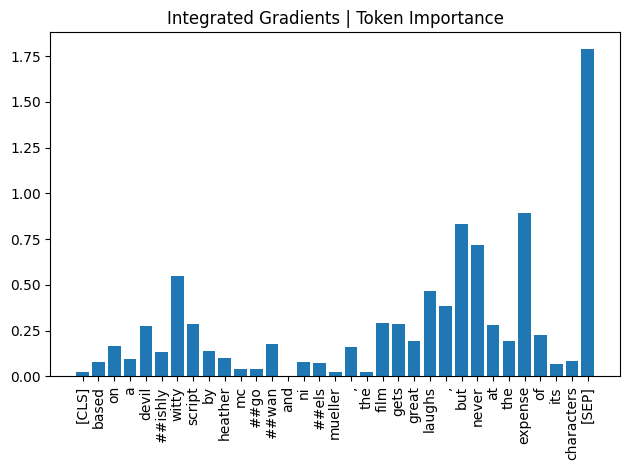

In [4]:

# 1) Integrated Gradients
tokens, ig = ig_attributions(SAMPLE, mdl, tok, target=cfg.target_label, device=cfg.device, max_len=cfg.max_len, steps=cfg.ig_steps)
print("IG top tokens:", [tokens[i] for i in np.argsort(-np.abs(ig))[:cfg.top_k]])
plot_token_importance(tokens, np.abs(ig), "Integrated Gradients | Token Importance")


In [5]:
# 2) LIME-Text
lime_pairs = lime_explain(SAMPLE, labels, pipe, num_features=10, num_samples=cfg.lime_num_samples)
print("LIME top pairs:", lime_pairs[:cfg.top_k])


`return_all_scores` is now deprecated,  if want a similar functionality use `top_k=None` instead of `return_all_scores=True` or `top_k=1` instead of `return_all_scores=False`.


LIME top pairs: [('witty', 0.15219789799052982), ('laughs', 0.11960227820283732), ('great', 0.11575792797567461), ('expense', 0.08255999783858217), ('but', -0.07265565985450687)]


In [6]:
# 3) SHAP-Text
shap_res = shap_explain([SAMPLE], pipe, max_evals=cfg.shap_max_evals)
print("SHAP value array shapes:", [v.shape for v in shap_res["values"]])

`return_all_scores` is now deprecated,  if want a similar functionality use `top_k=None` instead of `return_all_scores=True` or `top_k=1` instead of `return_all_scores=False`.
You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset
`return_all_scores` is now deprecated,  if want a similar functionality use `top_k=None` instead of `return_all_scores=True` or `top_k=1` instead of `return_all_scores=False`.
You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


SHAP value array shapes: [(25, 2)]


SC: {'baseline': 0.9991422891616821, 'sufficiency': 0.0020958520472049713, 'comprehensiveness': 0.10017549991607666}


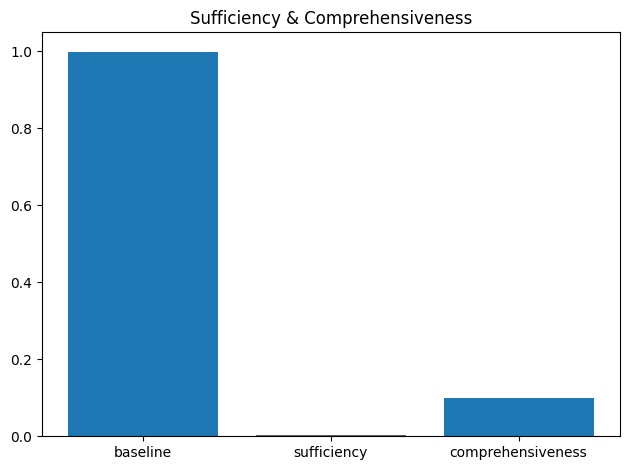

In [7]:
# 4) Sufficiency & Comprehensiveness
sc, top_idx = sufficiency_comprehensiveness(SAMPLE, ig, tokens, pipe, k=cfg.top_k, cls_index=cfg.target_label, tokenizer=tok, max_len=cfg.max_len)
print("SC:", sc)
plot_sc(sc, "Sufficiency & Comprehensiveness")

Rollout matrix shape: (33, 33)


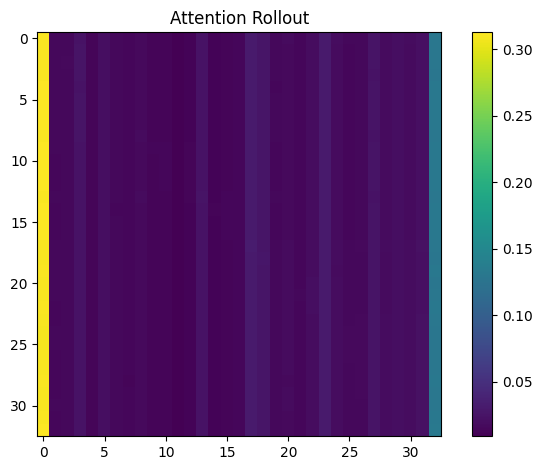

In [8]:
# 5) Attention Rollout
rt_tokens, rollout = attention_rollout(SAMPLE, mdl, tok, device=cfg.device, max_len=cfg.max_len)
print("Rollout matrix shape:", rollout.shape)
plot_rollout_matrix(rollout, "Attention Rollout")


In [9]:
# 6) Anchors-Text
if _ALIBI_OK:
    anch = anchors_text(SAMPLE, labels, pipe, threshold=0.9)
    print("Anchors:", anch)
else:
    print("Anchors skipped (install alibi & spacy to enable).")



The following keys are incorrect: use_unk_distribution


Anchors: {'anchor': ['witty', 'devilishly'], 'precision': 0.9784615384615385, 'coverage': 0.2542}


In [10]:
# 7) DiCE-Text (minimal-edit surrogate using MLM proposals)
dice = dice_text_min_edit(SAMPLE, target_label=cfg.target_label, pipe=pipe, tokenizer=tok, device=cfg.device, beam=50)
print("DiCE-like:", dice)

DiCE-like: {'base_already_target': True, 'text': 'based on a devilishly witty script by heather mcgowan and niels mueller , the film gets great laughs , but never at the expense of its characters ', 'probs': [0.0008576783584430814, 0.9991422891616821]}


In [11]:
# 8) Activation / Path Patching
specials = {tok.cls_token, tok.sep_token, tok.pad_token}
candidate_idx = [i for i in np.argsort(-np.abs(ig)).tolist() if tokens[i] not in specials][: cfg.top_k]
patched = activation_patching(
    text=SAMPLE,
    control_text="This is meaningless.",
    model=mdl,
    tokenizer=tok,
    target_label=cfg.target_label,
    layer_idx=cfg.layer_idx,
    token_indices=candidate_idx,
    device=cfg.device,
    max_len=cfg.max_len,
)
print("Activation patching:", patched)

Activation patching: {'base_prob': 0.9991422891616821, 'patched_prob': 0.9903738498687744, 'delta': -0.008768439292907715}


## 5. XAI Methods Interpretation

First, we prepared a set of N = 200 data samples and the corresponding model pipeline.

In [12]:
set_seed(2025)
tok, mdl, pipe = load_bert("textattack/bert-base-uncased-SST-2", cfg.device)
labels = get_label_names(mdl)
print("Labels:", labels)


ds = load_dataset(
    "parquet", 
    data_files="textattack/validation-00000-of-00001-02c8af09f7a87704.parquet"
)["train"].shuffle(seed=2025).select(range(200))

print("Loaded samples:", len(ds))

`resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.


Labels: ['LABEL_0', 'LABEL_1']
Loaded samples: 200


In [13]:
pipe = TextClassificationPipeline(model=mdl, tokenizer=tok, device=0)

pipe.device

device(type='cuda', index=0)

Next, we applied the XAI methods to obtain explanations for the dataset and saved the results into a JSON file. The execution of this code block takes approximately 15 minutes. If the file `xai_out/all_summaries.json`.json already exists in the current folder, the code will skip execution and directly use the existing results.

In [14]:
import json, os

os.makedirs("xai_out", exist_ok=True)
json_path = "xai_out/all_summaries.json"

if os.path.exists(json_path):
    print(f"{json_path} exists")
    with open(json_path, "r", encoding="utf-8") as f:
        all_summaries = json.load(f)
else:
    all_summaries = []

    for i, sample in enumerate(ds):
        text = sample["sentence"]
        gold_label = sample["label"]

        print(f"\n=== Processing sample {i} ===")
        print(text)

        # 1) IG
        tokens, ig_scores = ig_attributions(
            text=text,
            model=mdl,
            tokenizer=tok,
            target=gold_label,
            device=cfg.device,
            max_len=cfg.max_len,
            steps=cfg.ig_steps
        )

        # 2) SHAP
        shap_res = shap_explain([text], pipe, max_evals=cfg.shap_max_evals)
        vals = shap_res["values"][0]
        cls_id = gold_label
        vals_cls = vals[:, cls_id]

        # 3) SC
        sc_res, top_idx = sufficiency_comprehensiveness(
            text, ig_scores, tokens, pipe,
            k=cfg.top_k, cls_index=gold_label,
            tokenizer=tok,
            max_len=cfg.max_len
        )

        # 4) DiCE
        dice_res = dice_text_min_edit(
            text,
            target_label=1 - gold_label,
            pipe=pipe,
            tokenizer=tok,
            device=cfg.device,
            beam=50
        )

        # 5) Activation patching
        specials = {tok.cls_token, tok.sep_token, tok.pad_token}
        candidate_idx = [
            j for j in np.argsort(-np.abs(ig_scores))
            if tokens[j] not in specials
        ][: cfg.top_k]

        layers = [8, 9, 10]
        patched_results = {}

        for layer in layers:
            patched_res = activation_patching(
                text=text,
                control_text="This is meaningless.",
                model=mdl,
                tokenizer=tok,
                target_label=gold_label,
                layer_idx=layer,
                token_indices=candidate_idx,
                device=cfg.device,
                max_len=cfg.max_len,
            )
            patched_results[f"layer_{layer}"] = patched_res

        with torch.no_grad():
            outputs = pipe([text], top_k=None)
            output0 = outputs[0]
            best_item = max(output0, key=lambda x: x['score'])
            label_str = best_item['label']
            pred_label = int(label_str.split("_")[1])

        summary = {
            "text": text,
            "gold_label": gold_label,
            "pred_label": pred_label,
            "ig_top_tokens": [tokens[k] for k in np.argsort(-np.abs(ig_scores))[: cfg.top_k]],
            "shap_top_tokens": [tokens[k] for k in np.argsort(-np.abs(vals_cls))[: cfg.top_k]],
            "sufficiency": sc_res["sufficiency"],
            "comprehensiveness": sc_res["comprehensiveness"],
            "dice_edit": dice_res,
            "patched": {
                layer: res for layer, res in patched_results.items()
            },
        }

        all_summaries.append(summary)

    with open(json_path, "w", encoding="utf-8") as f:
        json.dump(all_summaries, f, indent=2, ensure_ascii=False)

    print(f"\nSaved: {json_path}")


xai_out/all_summaries.json exists


In [15]:
import json

with open("xai_out/all_summaries.json", "r", encoding="utf-8") as f:
    summaries = json.load(f)

for s in summaries:
    text = s["text"]
    gold = s["gold_label"]
    ig_tokens = s["ig_top_tokens"]
    shap_tokens = s["shap_top_tokens"]


## 1) Integrated Gradients

IG top tokens: ['[SEP]', 'expense', 'but', 'never', 'witty']


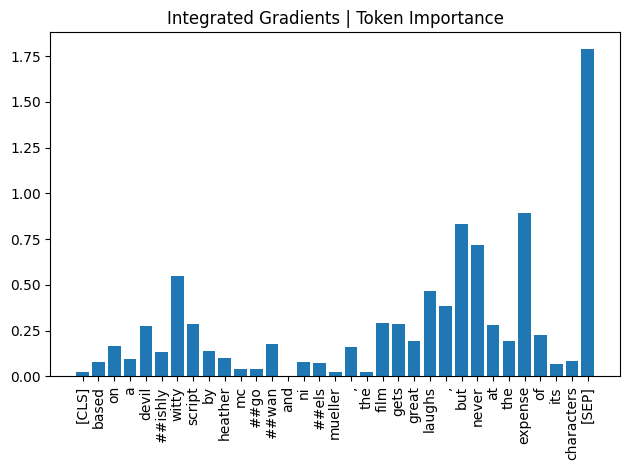

In [16]:

# 1) Integrated Gradients
tokens, ig = ig_attributions(SAMPLE, mdl, tok, target=cfg.target_label, device=cfg.device, max_len=cfg.max_len, steps=cfg.ig_steps)
print("IG top tokens:", [tokens[i] for i in np.argsort(-np.abs(ig))[:cfg.top_k]])
plot_token_importance(tokens, np.abs(ig), "Integrated Gradients | Token Importance")


In [17]:
# Enhanced IG visualization
def plot_ig_enhanced(tokens, ig_scores, target_label, title="Integrated Gradients"):
    """IG visualization with signed and cumulative contributions"""
    import matplotlib.pyplot as plt
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
    
    # 1. Signed bar chart
    colors = ['red' if s < 0 else 'green' for s in ig_scores]
    ax1.bar(range(len(tokens)), ig_scores, color=colors, alpha=0.7)
    ax1.axhline(y=0, color='black', linestyle='--', linewidth=0.8)
    ax1.set_xticks(range(len(tokens)))
    ax1.set_xticklabels(tokens, rotation=90)
    ax1.set_ylabel("IG Score (signed)")
    ax1.set_title(f"{title} - Signed Contributions (Target: LABEL_{target_label})")
    
    # Add statistics for positive vs. negative contributions
    pos_sum = np.sum(ig_scores[ig_scores > 0])
    neg_sum = np.sum(ig_scores[ig_scores < 0])
    ax1.text(0.02, 0.98, f"Total Positive: {pos_sum:.3f}\nTotal Negative: {neg_sum:.3f}", 
             transform=ax1.transAxes, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    # 2. Cumulative contribution curve
    cumulative = np.cumsum(ig_scores)
    ax2.plot(range(len(tokens)), cumulative, marker='o', linewidth=2)
    ax2.fill_between(range(len(tokens)), cumulative, alpha=0.3)
    ax2.axhline(y=0, color='black', linestyle='--', linewidth=0.8)
    ax2.axhline(y=cumulative[-1], color='blue', linestyle=':', 
                label=f'Final Score: {cumulative[-1]:.3f}')
    ax2.set_xticks(range(len(tokens)))
    ax2.set_xticklabels(tokens, rotation=90)
    ax2.set_ylabel("Cumulative IG")
    ax2.set_xlabel("Token Position")
    ax2.set_title("Cumulative Contribution Along Sequence")
    ax2.legend()
    
    plt.tight_layout()
    plt.show()


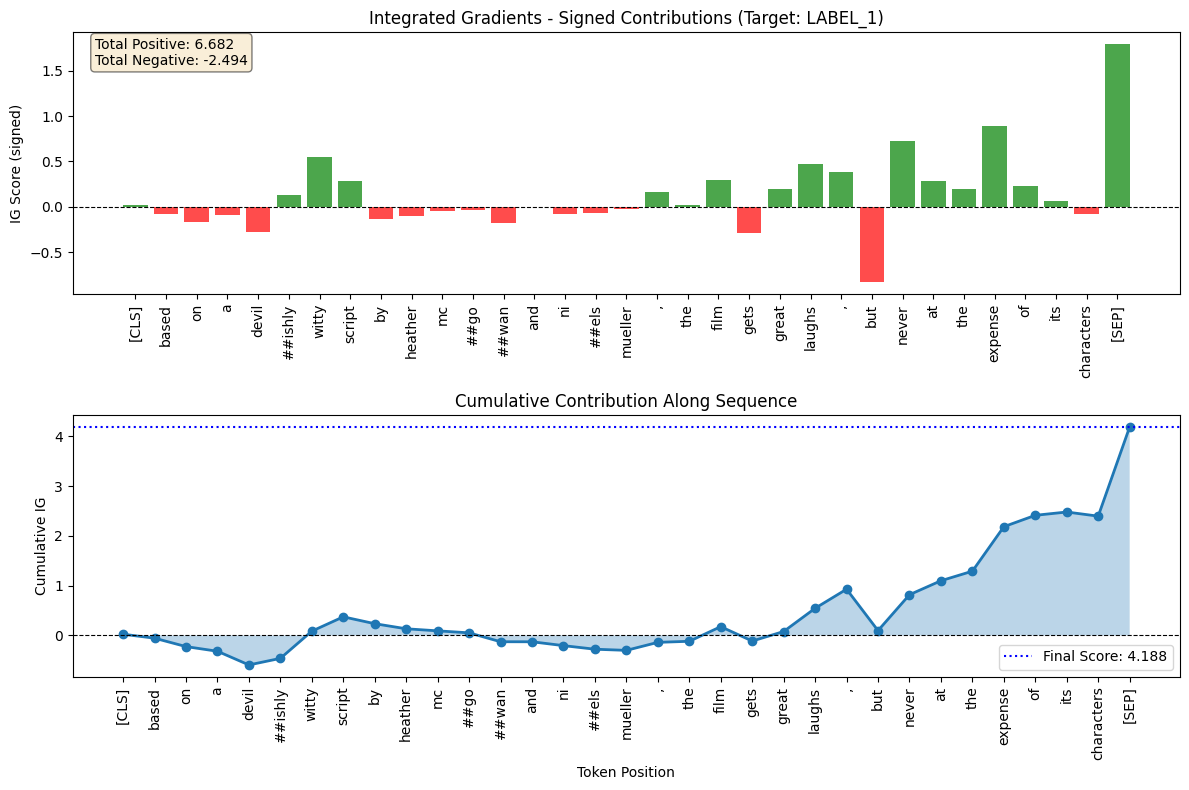

In [18]:
plot_ig_enhanced(tokens, ig, cfg.target_label)

**Top plot (Signed contributions)**  
   - Green bars denote tokens with positive contribution to the target label (LABEL\_1, positive), while red bars denote negative contributions.  
   - In the first half of the sentence (“based on a devilishly witty script … the film gets great laughs”), we see a mix of positive tokens (witty, great, laughs) and mildly negative or neutral ones, so the net effect is relatively balanced.  
   - In the second half (“but never at the expense of its characters”), most tokens (but, never, expense, characters, etc.) receive large absolute contributions, making this clause the **key decision region**.

**Bottom plot (Cumulative contribution curve)**  
   - The x-axis follows the token order while the y-axis accumulates IG scores. In the first half of the sentence, the cumulative value fluctuates around zero, indicating limited net impact on the final decision.  
   - Starting from “but”, the curve rises sharply and reaches its final value (~4.19) near “[SEP]”, showing that **the model commits to the positive prediction mainly based on the latter clause**.  
   - The shaded area highlights where cumulative contribution grows, helping us visually locate the most influential span.


### Pitfalls & Error Patterns of IG 

**Abnormally large attribution on special tokens (e.g., `[SEP]`)**  
   - In this example, `[SEP]` receives one of the largest IG scores, which is clearly uninformative from a semantic perspective.  
   - This often happens because:  
     - The embedding difference along the integration path is large for special tokens.  
     - The model relies heavily on positional or boundary markers (e.g., the last position acts as a global aggregator).  
   - **Such tokens should be filtered out or explicitly marked** during analysis to avoid misleading users into thinking `[SEP]` is “the most important word”.

2. **Subword granularity leads to fragmented explanations**  
   - Tokens like “devil ##ishy” are split into wordpieces; their IG scores are scattered, which is hard to interpret for non-experts.  
   - For error cases, this fragmentation makes it difficult to see which *whole word* actually misleads the model.  
   - A better practice is to **aggregate IG scores at the word level** (sum or average over subwords) before visualization.

3. **Negation and complex phrases can be locally misleading**  
   - Although this example handles “never at the expense of …” correctly, in other misclassified samples, expressions like “not bad” or “never boring” may show:  
     - Strong negative attribution on “not/never”, and  
     - Downstream evaluators over-focusing on the single negation token.  
   - Therefore, when analyzing errors, we must consider the **phrase-level meaning**, not just the sign of individual tokens.

4. **On misclassified samples, IG may highlight neutral or spurious evidence**  
   - When the model is wrong, IG typically assigns high scores to:  
     - Tokens that are semantically neutral, or  
     - Fragments that contradict human intuition.  
   - These samples are crucial for **diagnosing model biases**:  
     - If IG emphasizes tokens that correlate with label only in the training distribution (e.g., specific names/locations), the model is relying on spurious correlations.  
     - If it emphasizes punctuation or special tokens, the model may be over-fitting to formatting/position patterns.


### Error Analysis -IG

#### Typical failure patterns

1. **Abnormally large attribution on special tokens**
   - Tokens like `[CLS]` or `[SEP]` can receive the largest IG scores even though they carry almost no semantic content.
   - This is often caused by:
     - The integration path (from zero embedding to the real embedding) making special tokens move more in embedding space.
     - The architecture using those positions as global aggregation points.
   - If we blindly rank tokens by IG, we may mistakenly claim that `[SEP]` is “most important”.

2. **Fragmented attributions due to subwords**
   - BERT splits words into pieces (e.g., `devil ##ishly`).
   - IG scores are defined at the subword level, so the importance of one human word is scattered across multiple tokens.
   - On error cases it becomes hard to see which *word* actually misleads the model.

3. **Negation and compositional phrases**
   - IG works additively over tokens; it does not explicitly model interactions like “not bad”, “never boring”.
   - It can assign a strong negative score to “not/never” and a separate positive score to “bad/boring”.
   - If we only look at single tokens, we may think the model “only looks at the negation word”, while the phrase meaning is actually positive.

4. **Misclassified samples highlight spurious evidence**
   - When the model is wrong, IG faithfully shows *what the model relied on*, which can be:
     - Neutral or irrelevant words.
     - Spurious correlations (names, locations, punctuation patterns).
   - This is useful but easy to misread as “the explanation is wrong”, while it actually exposes the model’s bias.



#### **Suggestions for improvement (for error analysis)**

- **Down-weight or remove special tokens**: After computing IG, set the attribution of `[CLS]`, `[SEP]`, etc. to zero or handle them separately, and exclude them from top-k selection and Sufficiency/Comprehensiveness metrics.  
- **Aggregate attributions to the word level**: Merge subword scores back to original words, then re-rank; this yields more human-readable importance scores and aligns better with annotations/rules.  
- **Cross-validate with other XAI methods**: For each error case, compare IG with LIME, SHAP, and Attention Rollout. If multiple methods highlight the same odd fragment, it is more likely to reflect a genuine model bias.  
- **Use counterfactual edits**: For suspicious tokens highlighted by IG, manually or with DiCE/MLM replace them and check whether the prediction changes, to verify whether those tokens are truly causal for the decision.

---

## 2) LIME-Text

In [19]:
# 2) LIME-Text

lime_pairs = lime_explain(SAMPLE, labels, pipe, num_features=10, num_samples=cfg.lime_num_samples)
# lime_pairs = lime_explain(SAMPLE, labels, pipe, num_features=10, num_samples=cfg.lime_num_samples)
print("LIME top pairs:", lime_pairs[:cfg.top_k])


`return_all_scores` is now deprecated,  if want a similar functionality use `top_k=None` instead of `return_all_scores=True` or `top_k=1` instead of `return_all_scores=False`.


LIME top pairs: [('witty', 0.15219789799052982), ('laughs', 0.11960227820283732), ('great', 0.11575792797567461), ('expense', 0.08255999783858217), ('but', -0.07265565985450687)]


In [20]:
def lime_explain_enhanced(text: str, class_names: List[str], pipe, 
                          num_features: int = 20, num_samples: int = 1000,
                          **kwargs):
    """Enhanced LIME-Text that forces explanations for all classes"""
    from lime.lime_text import LimeTextExplainer
    import numpy as np
    from typing import List
    
    explainer = LimeTextExplainer(
        class_names=class_names,
        bow=False,
        random_state=42
    )
    
    # Key change: set labels argument to the indices of all classes
    # This forces LIME to generate explanations for every class
    exp = explainer.explain_instance(
        text,
        classifier_fn=lambda xs: predict_proba_single(pipe, xs),
        num_features=num_features,
        num_samples=num_samples,
        labels=list(range(len(class_names))),  # add this line!
        **kwargs
    )
    
    # ========== Diagnose LIME label mapping ==========
    print(f"\n=== LIME Debug Info ===")
    print(f"LIME mode: {exp.mode}")
    print(f"Available labels in local_exp: {list(exp.local_exp.keys())}")
    print(f"Predicted proba: {exp.predict_proba}")
    print(f"Class names: {class_names}")
    
    # Get correct label mapping
    explanations = {}
    for class_id, class_name in enumerate(class_names):
        try:
            # Try integer index (older LIME versions)
            features = exp.as_list(label=class_id)
            prob = exp.predict_proba[class_id]
            
        except (KeyError, IndexError):
            # If that fails, try using class_name as key
            try:
                features = exp.as_list(label=class_name)
                prob = exp.predict_proba[class_id] if isinstance(exp.predict_proba, (list, np.ndarray)) else \
                       dict(exp.predict_proba).get(class_name, 0)
            except:
                # Last resort: try to infer from predict_proba
                if hasattr(exp.predict_proba, 'shape') and len(exp.predict_proba.shape) > 0:
                    # If it is a list/array, access by index
                    prob = exp.predict_proba[class_id]
                else:
                    # If it is a dict, access by name
                    prob = dict(exp.predict_proba).get(class_name, 0)
                
                # If we still cannot get the feature, skip it
                print(f"  Warning: Could not get features for {class_name}, using empty list")
                features = []
        
        explanations[class_name] = {
            'features': features,
            'probability': float(prob),
            'class_id': class_id
        }
    
    return {
        'explanation_obj': exp,
        'explanations': explanations,
        'text': text,
        'predicted_class': class_names[np.argmax(exp.predict_proba) if hasattr(exp.predict_proba, '__len__') else 0]
    }

In [21]:
def predict_proba_single(pipe: TextClassificationPipeline, texts: List[str]) -> np.ndarray:
    """Patched version: compatible with newer transformers versions"""
    # Note: return_all_scores=True is deprecated; use top_k=None instead
    out = pipe(texts, top_k=None)  # return scores for all classes
    probs = []
    for sample in out:
        # Sort by number of classes to keep order consistent
        if isinstance(sample, list):
            # Already in list format
            sorted_probs = [d['score'] for d in sorted(sample, key=lambda x: x['label'])]
        else:
            # Single dict, may be top-1 output
            sorted_probs = [sample['score']]
        probs.append(sorted_probs)
    
    return np.array(probs, dtype=np.float32)

In [22]:
def plot_lime_detailed(lime_result, class_names, top_k=15):
    """Multi-dimensional LIME visualization (patched version)"""
    import matplotlib.pyplot as plt
    import numpy as np
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle(f"LIME Detailed Analysis - '{lime_result['text'][:50]}...'", fontsize=16)
    
    # 1. Compare feature weights for all classes (skip empty classes)
    ax1 = axes[0, 0]
    tokens = []  # initialize tokens to avoid undefined variable after the loop
    for i, class_name in enumerate(class_names):
        features = lime_result['explanations'][class_name]['features'][:top_k]
        if not features:  # if feature list is empty, skip
            print(f"  Warning: No features for {class_name}, skipping in subplot 1")
            continue
            
        tokens = [f[0] for f in features]
        weights = [f[1] for f in features]
        
        ax1.barh(range(len(tokens)), weights, 
                label=f"{class_name} (p={lime_result['explanations'][class_name]['probability']:.3f})",
                alpha=0.7)
    
    if tokens:  # only set yticks when there is data
        ax1.set_yticks(range(len(tokens)))
        ax1.set_yticklabels(tokens)
    ax1.set_xlabel("Weight")
    ax1.set_title("Top Features by Class")
    ax1.legend()
    ax1.axvline(x=0, color='black', linestyle='--')
    
    # 2. Detailed weights for the predicted class (only when there is data)
    ax2 = axes[0, 1]
    pred_class = lime_result['predicted_class']
    features = lime_result['explanations'][pred_class]['features'][:top_k]
    
    if not features:  # if even the predicted class has no features, use a fallback
        print(f" Error: Even predicted class {pred_class} has no features!")
        tokens, weights = ["No features"], [0]
    else:
        tokens = [f[0] for f in features]
        weights = [f[1] for f in features]
    
    colors = ['green' if w > 0 else 'red' for w in weights]
    bars = ax2.barh(range(len(tokens)), weights, color=colors, alpha=0.7)
    
    for i, (bar, w) in enumerate(zip(bars, weights)):
        ax2.text(w + (0.001 if w > 0 else -0.001), i, f'{w:.3f}', 
                va='center', ha='left' if w > 0 else 'right', fontsize=8)
    
    ax2.set_yticks(range(len(tokens)))
    ax2.set_yticklabels(tokens)
    ax2.set_xlabel("Weight")
    ax2.set_title(f"Predicted Class: {pred_class}")
    ax2.axvline(x=0, color='black', linestyle='--')
    
    # 3. Weight-distribution histogram (skip empty classes)
    ax3 = axes[1, 0]
    has_data = False
    for class_name in class_names:
        weights = [f[1] for f in lime_result['explanations'][class_name]['features']]
        if weights:  # only plot when there is data
            ax3.hist(weights, bins=20, alpha=0.5, label=class_name)
            has_data = True
    
    if not has_data:
        ax3.text(0.5, 0.5, 'No features available', ha='center', va='center', transform=ax3.transAxes)
    
    ax3.set_xlabel("Weight")
    ax3.set_ylabel("Frequency")
    ax3.set_title("Weight Distribution")
    ax3.legend()
    
    # 4. Cumulative explanatory power curve (skip empty classes)
    ax4 = axes[1, 1]
    has_curve = False
    for class_name in class_names:
        features = lime_result['explanations'][class_name]['features']
        if not features:  # skip empty list
            print(f"  Warning: Skipping {class_name} in cumulative power plot (no features)")
            continue
        
        cumsum = np.cumsum([abs(f[1]) for f in features])
        if cumsum[-1] == 0:  # avoid division by zero
            continue
        cumsum = cumsum / cumsum[-1]  # normalize
        
        ax4.plot(range(1, len(cumsum) + 1), cumsum, marker='o', label=class_name)
        has_curve = True
    
    if not has_curve:
        ax4.text(0.5, 0.5, 'No valid data for curves', ha='center', va='center', transform=ax4.transAxes)
    
    ax4.set_xlabel("Number of Top Features")
    ax4.set_ylabel("Cumulative |Weight|")
    ax4.set_title("Cumulative Explanatory Power")
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [23]:
result = lime_explain_enhanced(
    SAMPLE, labels, pipe,
    num_features=30,
    num_samples=cfg.lime_num_samples
)


=== LIME Debug Info ===
LIME mode: classification
Available labels in local_exp: [0, 1]
Predicted proba: [8.5767836e-04 9.9914229e-01]
Class names: ['LABEL_0', 'LABEL_1']


- The local linear model learned by LIME is highly confident:  
  `Predicted proba ≈ [0.0009, 0.999]`, so the instance is almost surely **positive (LABEL_1)**.
- In **Top Features by Class**:  
  - For the positive class LABEL_1, the highest weights are assigned to words such as **“witty”**, **“never”**, **“laughs”**, **“devilishly”**, **“great”**, **“expense”**, etc.  
  - For the negative class LABEL_0, most weights are roughly mirrored, i.e., the same tokens now push the prediction away from class 0, which is expected for a two-class linear model.
- In the **Predicted Class: LABEL_1** panel:  
  - Positive (green) weights are concentrated on clearly positive or crucial words/phrases, such as **“witty”**, **“laughs”**, **“great”**, **“never”**, and **“characters”**, indicating that LIME captures the main positive evidence in the sentence.  
  - A few tokens like **“expense”** and **“but”** receive negative weights, meaning that in the local linear approximation they slightly weaken the positive prediction.
- The **Weight Distribution** and **Cumulative Explanatory Power** plots show that:  
  - Most features have small weights around zero; only a handful carry substantial influence.  
  - The top ~10–15 features already account for the majority of total explanatory power, which justifies focusing on top-k features.


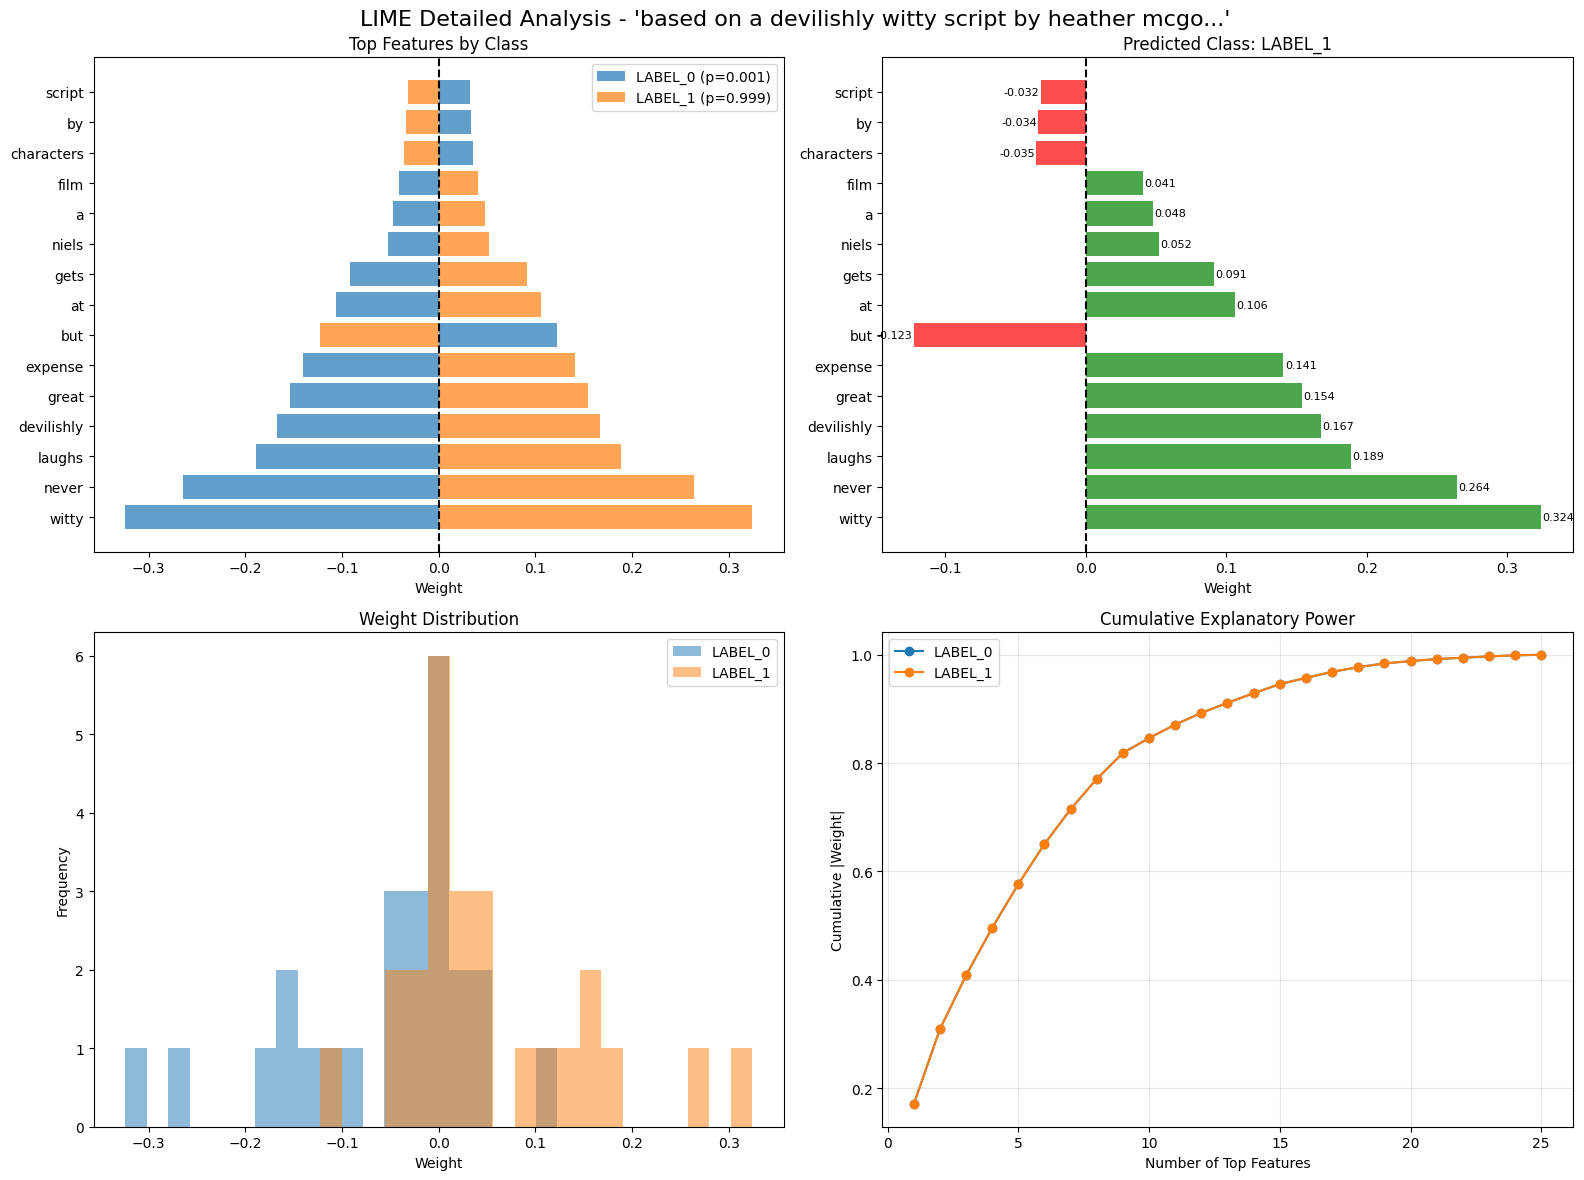

In [24]:
plot_lime_detailed(result, labels, top_k=15)

### Detailed Reading of the Four Panels

#### Top Features by Class
- Each row corresponds to one token/phrase; the left and right bars show the linear weight for **LABEL_0** and **LABEL_1** respectively.  
- Longer bars indicate stronger influence on the corresponding class in the local model.  
- We observe that:  
  - For **LABEL_1**, tokens like **“witty”**, **“never”**, and **“laughs”** have large positive weights.  
  - For **LABEL_0**, these same tokens have large negative weights, pulling the prediction away from the negative class.  
- This panel illustrates how the same text exerts opposite pulls in the two class directions.

#### Predicted Class Explanation
- This panel focuses solely on the **predicted class LABEL_1**.  
- Green bars: tokens whose presence increases the probability of LABEL_1;  
  Red bars: tokens whose presence decreases it.  
- In this instance:  
  - **“witty”**, **“never”**, **“laughs”**, **“devilishly”**, **“great”**, and **“characters”** provide the main positive evidence.  
  - **“expense”** and **“but”** receive negative weights, slightly pulling the probability down, possibly because in the sampled perturbations they tend to co-occur with more complex or even negative contexts.

#### Weight Distribution
- This histogram shows the frequency distribution of feature weights for each class.  
- Most weights cluster around zero, indicating that the LIME model is sparse: only a few tokens are truly important while the rest have negligible influence.  
- For error analysis, this suggests we can safely focus on tokens with large absolute weights.

#### Cumulative Explanatory Power
- The x-axis is the number of top features included (ranked by |weight|), and the y-axis is the cumulative |weight|, which can be interpreted as cumulative explanatory power.  
- The curve quickly rises and then saturates after around 10–15 features, indicating that **a small subset of features captures most of the local decision**.  
- This matches human intuition: only a handful of sentiment-bearing words truly matter in this review.



### LIME Pitfalls & Error Patterns


1. **Sampling sensitivity & instability**  
   - LIME builds a neighborhood by randomly masking or removing words, often producing ungrammatical or unnatural sentences.  
   - For sentences with negation or long-range dependencies, different random seeds may yield quite different linear models, resulting in **unstable attributions**.  
   - On misclassified instances, this may appear as “key tokens” changing from run to run, making the explanation unreliable.

2. **Limitations of local linear approximation**  
   - The underlying BERT model is highly non-linear, whereas LIME uses a single linear model to approximate local behavior.  
   - For phrases like “but never at the expense …”, which depend on compositional meaning, a linear model tends to spread credit across multiple tokens and ignore **interaction effects**.  
   - In error cases, this may cause neutral tokens to carry big weights or break down a crucial phrase into several less interpretable pieces.

3. **Mismatch between feature space and subwords**  
   - The explainer works at the surface word level, while BERT internally uses wordpieces.  
   - For rare words and proper nouns, this mismatch can be severe; the “remove/keep” operations in LIME may not faithfully reflect the model’s actual processing, leading to explanations that look plausible but deviate from the true mechanism.

4. **Misleading interpretation of the weak class**  
   - Here, LABEL\_0 has a tiny predicted probability (≈ 0.001), yet the **Top Features by Class** plot still shows a full set of weights for it.  
   - Non-expert users may misread this as the model seriously balancing evidence for both classes.  
   - For analysis, it is usually better to:  
     - focus on the **predicted class** explanation, and  
     - treat the other class’s weights mainly as a contrast, not as equally strong evidence.

5. **Typical patterns on misclassified samples**  
   - When the model mislabels neutral text, LIME often:  
     - forces a linear explanation on neutral words (giving them seemingly meaningful positive/negative weights), and  
     - highlights spurious tokens that co-occur with a certain label in the training data.  



**Practical recommendations**

- **Run LIME multiple times and check stability**; trust only features that consistently show up with large weights.  
- **Cross-check with IG, Attention Rollout, and Anchors**; if several methods highlight the same span, the signal is more trustworthy.  
- **Limit interpretation to the predicted class** when probabilities are extreme.  
- **Use counterfactual edits** (via DiCE or manual rewriting) to verify whether LIME’s high-weight tokens are truly causal for the prediction.

## 3) SHAP-Text

In [25]:
# 3) SHAP
from collections import Counter
import string
STOPWORDS = {
    "i", "me", "my", "myself", "we", "our", "ours", "ourselves", "you", "your",
    "yours", "yourself", "yourselves", "he", "him", "his", "himself", "she", "her",
    "hers", "herself", "it", "its", "itself", "they", "them", "their", "theirs",
    "themselves", "what", "which", "who", "whom", "this", "that", "these", "those",
    "am", "is", "are", "was", "were", "be", "been", "being", "have", "has", "had",
    "having", "do", "does", "did", "doing", "a", "an", "the", "and", "but", "if",
    "or", "because", "as", "until", "while", "of", "at", "by", "for", "with", "about",
    "against", "between", "into", "through", "during", "before", "after", "above",
    "below", "to", "from", "up", "down", "in", "out", "on", "off", "over", "under",
    "again", "further", "then", "once", "here", "there", "when", "where", "why",
    "how", "all", "any", "both", "each", "few", "more", "most", "other", "some",
    "such", "no", "nor", "not", "only", "own", "same", "so", "than", "too", "very",
    "s", "t", "can", "will", "just", "don", "should", "now"
}


TOP_K = 10

# -----------------------------
# token -> spans
# -----------------------------
def tokens_to_spans(text, top_tokens):
    words = text.split()
    spans = []
    current_span = []
    for w in words:
        if w in top_tokens and w.lower() not in STOPWORDS and w not in string.punctuation:
            current_span.append(w)
        else:
            if current_span:
                spans.append(" ".join(current_span))
                current_span = []
    if current_span:
        spans.append(" ".join(current_span))
    return spans


global_span_counter = Counter()

for summary in summaries:
    text = summary["text"]
    
    # IG top tokens
    ig_tokens = summary.get("ig_top_tokens", [])[:TOP_K]
    ig_spans = tokens_to_spans(text, ig_tokens)
    
    # SHAP top tokens
    shap_tokens = summary.get("shap_top_tokens", [])[:TOP_K]
    shap_spans = tokens_to_spans(text, shap_tokens)
    
    # global counter
    # global_span_counter.update(ig_spans)
    global_span_counter.update(shap_spans)




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



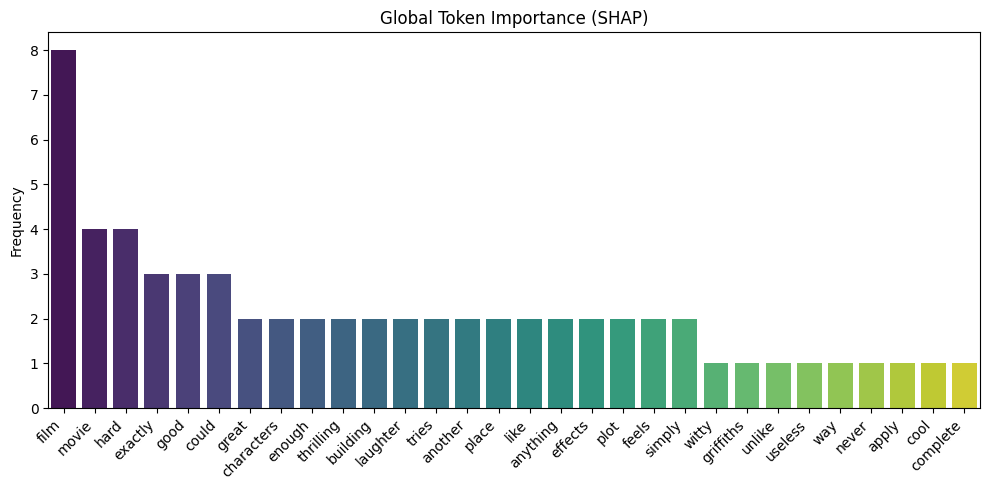

In [26]:
import seaborn as sns
top_spans = global_span_counter.most_common(30)
top_tokens, counts = zip(*top_spans)

plt.figure(figsize=(10,5))
sns.barplot(x=list(top_tokens), y=list(counts), palette="viridis")
plt.xticks(rotation=45, ha='right')
plt.ylabel("Frequency")
plt.title("Global Token Importance (SHAP)")
plt.tight_layout()
plt.show()

### **Global Analysis**
The model’s globally most important tokens are not all sentiment words. Tokens such as *film, movie, one, report,* and *much* appear frequently, indicating that the model may rely on topic or structural cues when making predictions. This could also reflect dataset biases, as these common words appear at different frequencies in positive and negative samples and are thus used by the model as auxiliary signals. However, a few sentiment words, such as *like, great, thrilling,* and *lovely*, also appear among the high-frequency tokens; these few sentiment words or negations can strongly influence the model’s predictions.

In [27]:
error_samples = [s for s in summaries if s.get("pred_label") != s.get("gold_label")]
print("Number of error samples:", len(error_samples))

for s in error_samples[:5]:
    # print("IG:", s.get("ig_top_tokens"))
    print("SHAP:", s.get("shap_top_tokens"))


Number of error samples: 19
SHAP: ['##ield', 'holden', '##ulf', '[CLS]', 'ca']
SHAP: ['good', '[CLS]', 'stupid', 'the', 'category']
SHAP: ['quite', 'its', '[CLS]', 'to', 'manages']
SHAP: ['build', 's', 'about', 'it', 'solid']
SHAP: ['[CLS]', 'although', ',', 'it', '##pper']




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



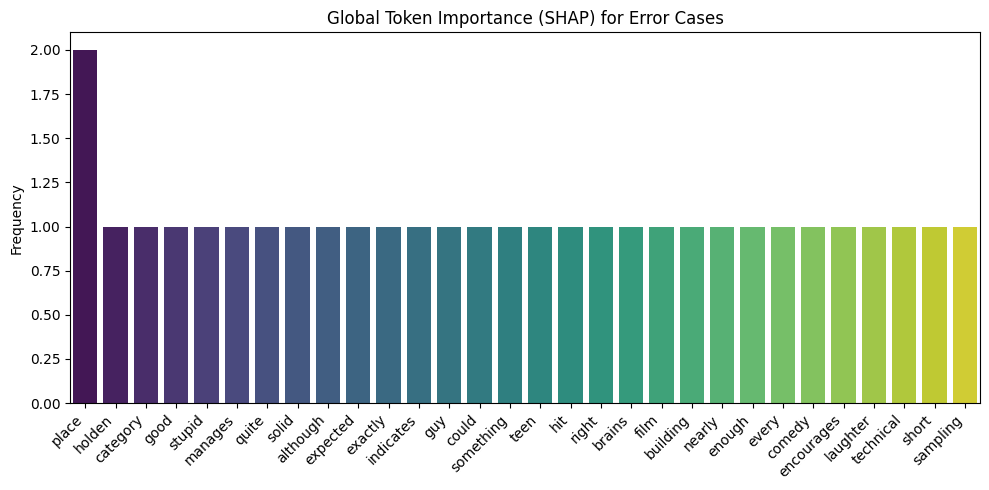

In [28]:
global_span_counter = Counter()

for s in summaries:
    text = s["text"]
    gold = s["gold_label"]

    pred = s.get("pred_label", None)
    if pred is None or pred == gold:
        continue

    # top tokens
    ig_tokens = s.get("ig_top_tokens", [])
    shap_tokens = s.get("shap_top_tokens", [])
    # top_tokens = set(ig_tokens + shap_tokens)
    top_tokens = set(shap_tokens)

    words = text.split()
    for w in words:
        if w.lower() not in STOPWORDS and w not in string.punctuation:
            if w in top_tokens:
                global_span_counter[w] += 1


top_spans = global_span_counter.most_common(30)
top_tokens, counts = zip(*top_spans)

plt.figure(figsize=(10,5))
sns.barplot(x=list(top_tokens), y=list(counts), palette="viridis")
plt.xticks(rotation=45, ha='right')
plt.ylabel("Frequency")
plt.title("Global Token Importance (SHAP) for Error Cases")
plt.tight_layout()
plt.show()

In the error samples, the high-frequency tokens are mostly sentiment words or negations, indicating that the model is particularly sensitive to these words and may misinterpret the context or overlook other key information. 

### **Local Analysis**

In the local analysis, we focused on selecting error cases for examination.


=== Error Sample 0 ===
Text: holden caulfield did it better . 
Gold label: 0 Pred label: 1


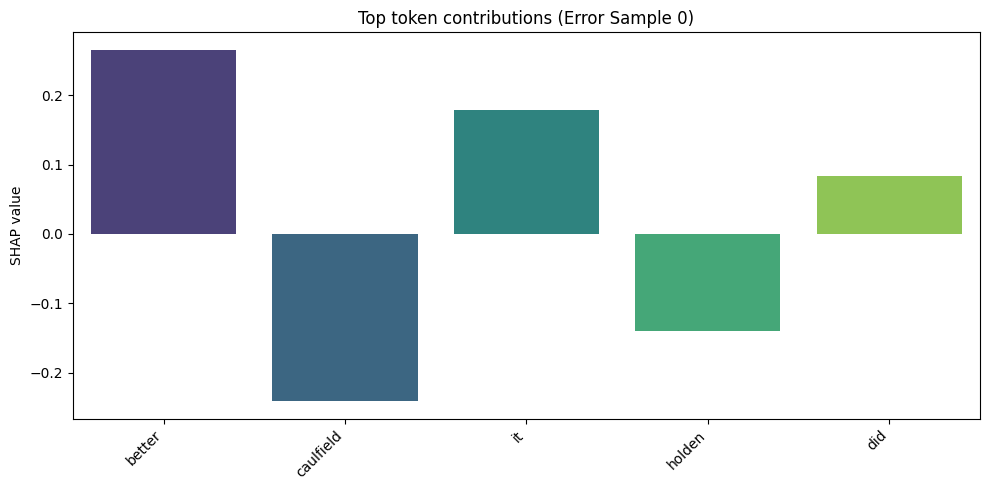


=== Error Sample 1 ===
Text: falls neatly into the category of good stupid fun . 
Gold label: 1 Pred label: 0


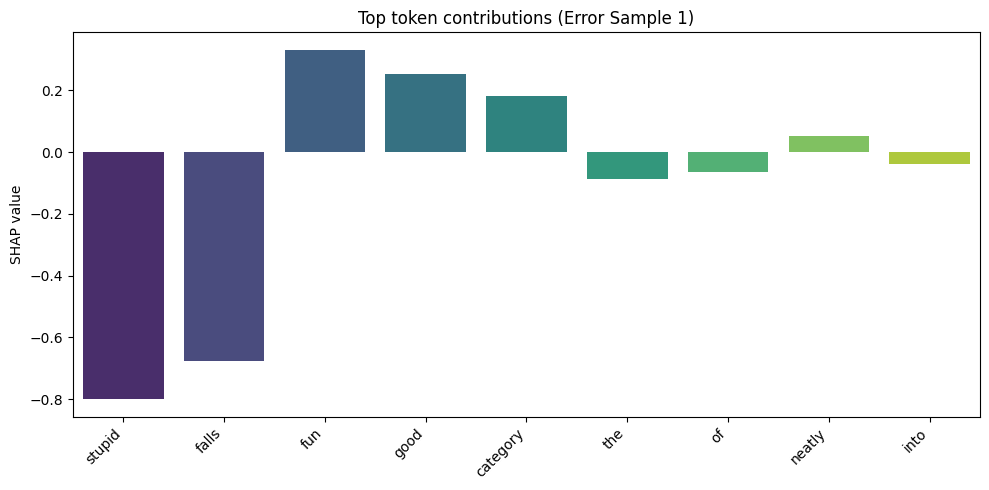

In [29]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

error_summaries = [s for s in summaries if s.get("pred_label") is not None and s["pred_label"] != s["gold_label"]]
error_summaries = error_summaries[:2]

for i, s in enumerate(error_summaries):
    text = s["text"]
    gold = s["gold_label"]
    pred = s["pred_label"]

    print(f"\n=== Error Sample {i} ===")
    print("Text:", text)
    print("Gold label:", gold, "Pred label:", pred)

    shap_res = shap_explain([text], pipe, max_evals=cfg.shap_max_evals)
    vals = shap_res["values"][0]
    vals_cls = vals[:, gold]

    tokens = text.split()
    top_k = 10
    top_idx = np.argsort(-np.abs(vals_cls))[:top_k]

    plt.figure(figsize=(10,5))
    sns.barplot(x=[tokens[j] for j in top_idx], y=[vals_cls[j] for j in top_idx], palette="viridis")
    plt.xticks(rotation=45, ha='right')
    plt.ylabel("SHAP value")
    plt.title(f"Top token contributions (Error Sample {i})")
    plt.tight_layout()
    plt.show()

For **Error Sample 0**, the model was "misled" by the word better, classifying the whole sentence as class 1 (positive sentiment). However, the actual meaning of the sentence, *"holden caulfield did it better,"* is a comparative statement, indicating that the current subject did not perform as well as "Holden Caulfield," which should correspond to negative sentiment.

In **Error Sample 1**, the model was misled by the words stupid and falls, which carry negative connotations out of context. The intended meaning of the sentence is that, *although the work may be a bit silly or unserious, it is indeed the kind of entertainment that is enjoyable and fun*, expressing a positive sentiment.

In summary, the model is easily influenced by words with obvious emotional connotations and fails to understand the sentiment in the context of the entire sentence, indicating a lack of sentence-level comprehension and contextual integration.

---


## 4) Explanation Evaluation

**Sufficiency** and **Comprehensiveness** are metrics for evaluating explanation quality, which evaluate whether the explanation captures features that are *sufficient* and *necessary* for the model’s decision.

=== Global Statistics ===
Sufficiency: mean=0.746, median=0.993, std=0.389
Comprehensiveness: mean=0.134, median=0.001, std=0.337


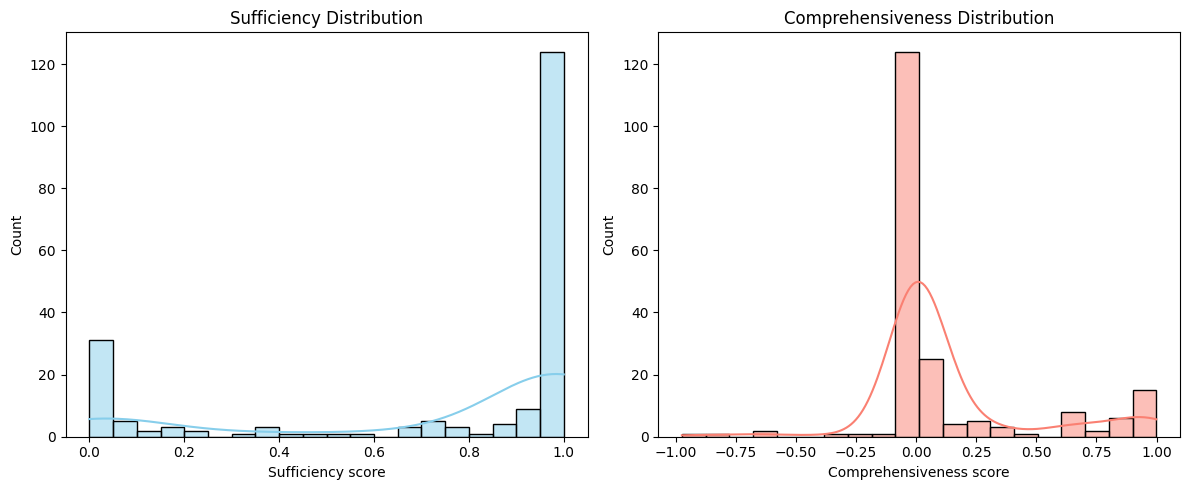

In [30]:
# 4) sufficiency & comprehensiveness
from collections import defaultdict

suff_vals = []
comp_vals = []
labels = []

for s in summaries:
    suff = s.get("sufficiency")
    comp = s.get("comprehensiveness")
    label = s.get("gold_label", None)
    if suff is not None and comp is not None:
        suff_vals.append(suff)
        comp_vals.append(comp)
        labels.append(label)

suff_vals = np.array(suff_vals)
comp_vals = np.array(comp_vals)
labels = np.array(labels)


print("=== Global Statistics ===")
print(f"Sufficiency: mean={suff_vals.mean():.3f}, median={np.median(suff_vals):.3f}, std={suff_vals.std():.3f}")
print(f"Comprehensiveness: mean={comp_vals.mean():.3f}, median={np.median(comp_vals):.3f}, std={comp_vals.std():.3f}")


plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
sns.histplot(suff_vals, bins=20, color='skyblue', kde=True)
plt.title("Sufficiency Distribution")
plt.xlabel("Sufficiency score")
plt.ylabel("Count")

plt.subplot(1,2,2)
sns.histplot(comp_vals, bins=20, color='salmon', kde=True)
plt.title("Comprehensiveness Distribution")
plt.xlabel("Comprehensiveness score")
plt.ylabel("Count")

plt.tight_layout()
plt.show()


### **Global Statistics**
Sufficiency is very high, meaning that for most samples, keeping only the top-attribution tokens is enough to almost fully reproduce the model’s prediction.  
Comprehensiveness is extremely low, indicating that removing high-attribution tokens does *not* significantly reduce the prediction probability, suggesting strong feature redundancy or backup trigger tokens in the model.

### **Distribution Patterns**  
Sufficiency shows a U-shaped distribution: most samples rely on only a few crucial tokens, while a minority cannot be reconstructed by the selected tokens, implying hidden or out-of-distribution patterns—an indicator of *extreme decision behavior*.  
In the Comprehensiveness distribution, a large number of values near 0 show that removing important tokens barely changes predictions. The fact that positive scores outnumber negative ones means the removed tokens do contribute, making the model slightly “less confident,” but the effect remains limited.


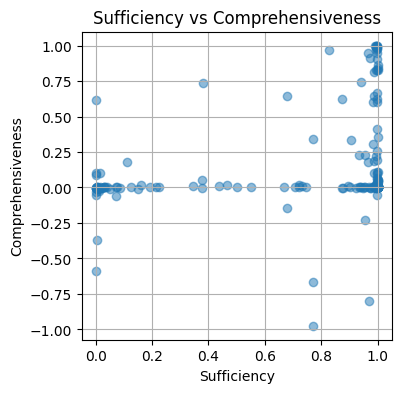

In [31]:
# Sufficiency vs Comprehensiveness
plt.figure(figsize=(4,4))
plt.scatter(suff_vals, comp_vals, alpha=0.5)
plt.xlabel("Sufficiency")
plt.ylabel("Comprehensiveness")
plt.title("Sufficiency vs Comprehensiveness")
plt.grid(True)
plt.show()


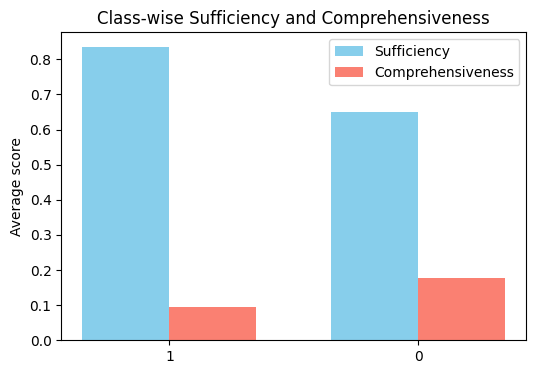

In [32]:

# Class-wise comparison
if labels is not None and any(labels):
    class_metrics = defaultdict(lambda: {"suff": [], "comp": []})
    for lab, s_val, c_val in zip(labels, suff_vals, comp_vals):
        class_metrics[lab]["suff"].append(s_val)
        class_metrics[lab]["comp"].append(c_val)

    classes = list(class_metrics.keys())
    suff_class = [np.mean(class_metrics[c]["suff"]) for c in classes]
    comp_class = [np.mean(class_metrics[c]["comp"]) for c in classes]

    x = np.arange(len(classes))
    width = 0.35

    plt.figure(figsize=(6,4))
    plt.bar(x - width/2, suff_class, width, label="Sufficiency", color='skyblue')
    plt.bar(x + width/2, comp_class, width, label="Comprehensiveness", color='salmon')
    plt.xticks(x, classes)
    plt.ylabel("Average score")
    plt.title("Class-wise Sufficiency and Comprehensiveness")
    plt.legend()
    plt.show()

### **Overall Interpretation**  
The model behaves as a redundancy-heavy local-feature classifier: local triggers + multiple backup pathways.

### **Class-wise Differences**  
Positive-class Sufficiency is higher, indicating that positive predictions depend more on a few strong sentiment words.  
Negative-class Comprehensiveness is higher, implying more diverse linguistic patterns for negative samples, so removing top-attribution tokens has a more noticeable (but still limited) effect.

---

## 5) Attention Rollout

Rollout matrix shape: (33, 33)


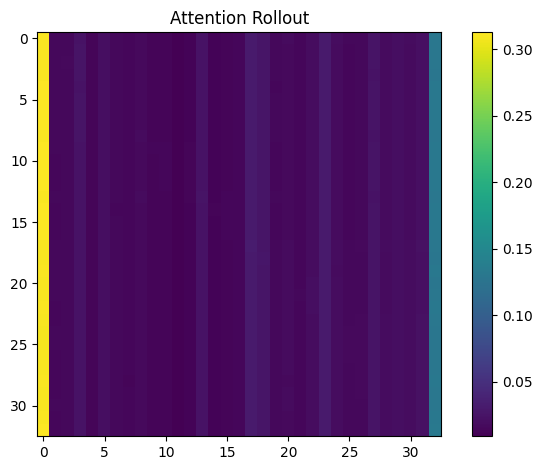

In [33]:
# 5) Attention Rollout
rt_tokens, rollout = attention_rollout(SAMPLE, mdl, tok, device=cfg.device, max_len=cfg.max_len)
print("Rollout matrix shape:", rollout.shape)
plot_rollout_matrix(rollout, "Attention Rollout")


- The rollout matrix has shape `(33, 33)`, capturing **aggregated attention flow** between 33 tokens of the current input.  
- From the heatmaps we observe that:  
  - The first column (attending to `[CLS]`) and the last column (attending to `[SEP]`) are markedly brighter, indicating that **most attention eventually converges to `[CLS]` and partly `[SEP]`**.  
  - Attention among other tokens is relatively small and diffuse; there is no clearly highlighted semantic span.  
- From the statistics:  
  - `Average Attention ≈ 0.0303`, `Max Attention ≈ 0.3126`; most entries are small with only a few links reaching around 0.3.  
  - `Sparsity (<0.01) ≈ 3%` suggests the matrix is not highly sparse; many entries carry some non-zero attention.  
  - “Top Source Tokens” all have total attention ≈ `1.0000002`, because row-normalization and residual connections enforce each token to emit roughly one unit of attention; hence **source-importance is more of a sanity check than an explanatory signal**.  
  - “Top Target Tokens” show that `[CLS]` and `[SEP]` dominate the received attention, confirming that the model aggregates information primarily at these special positions.


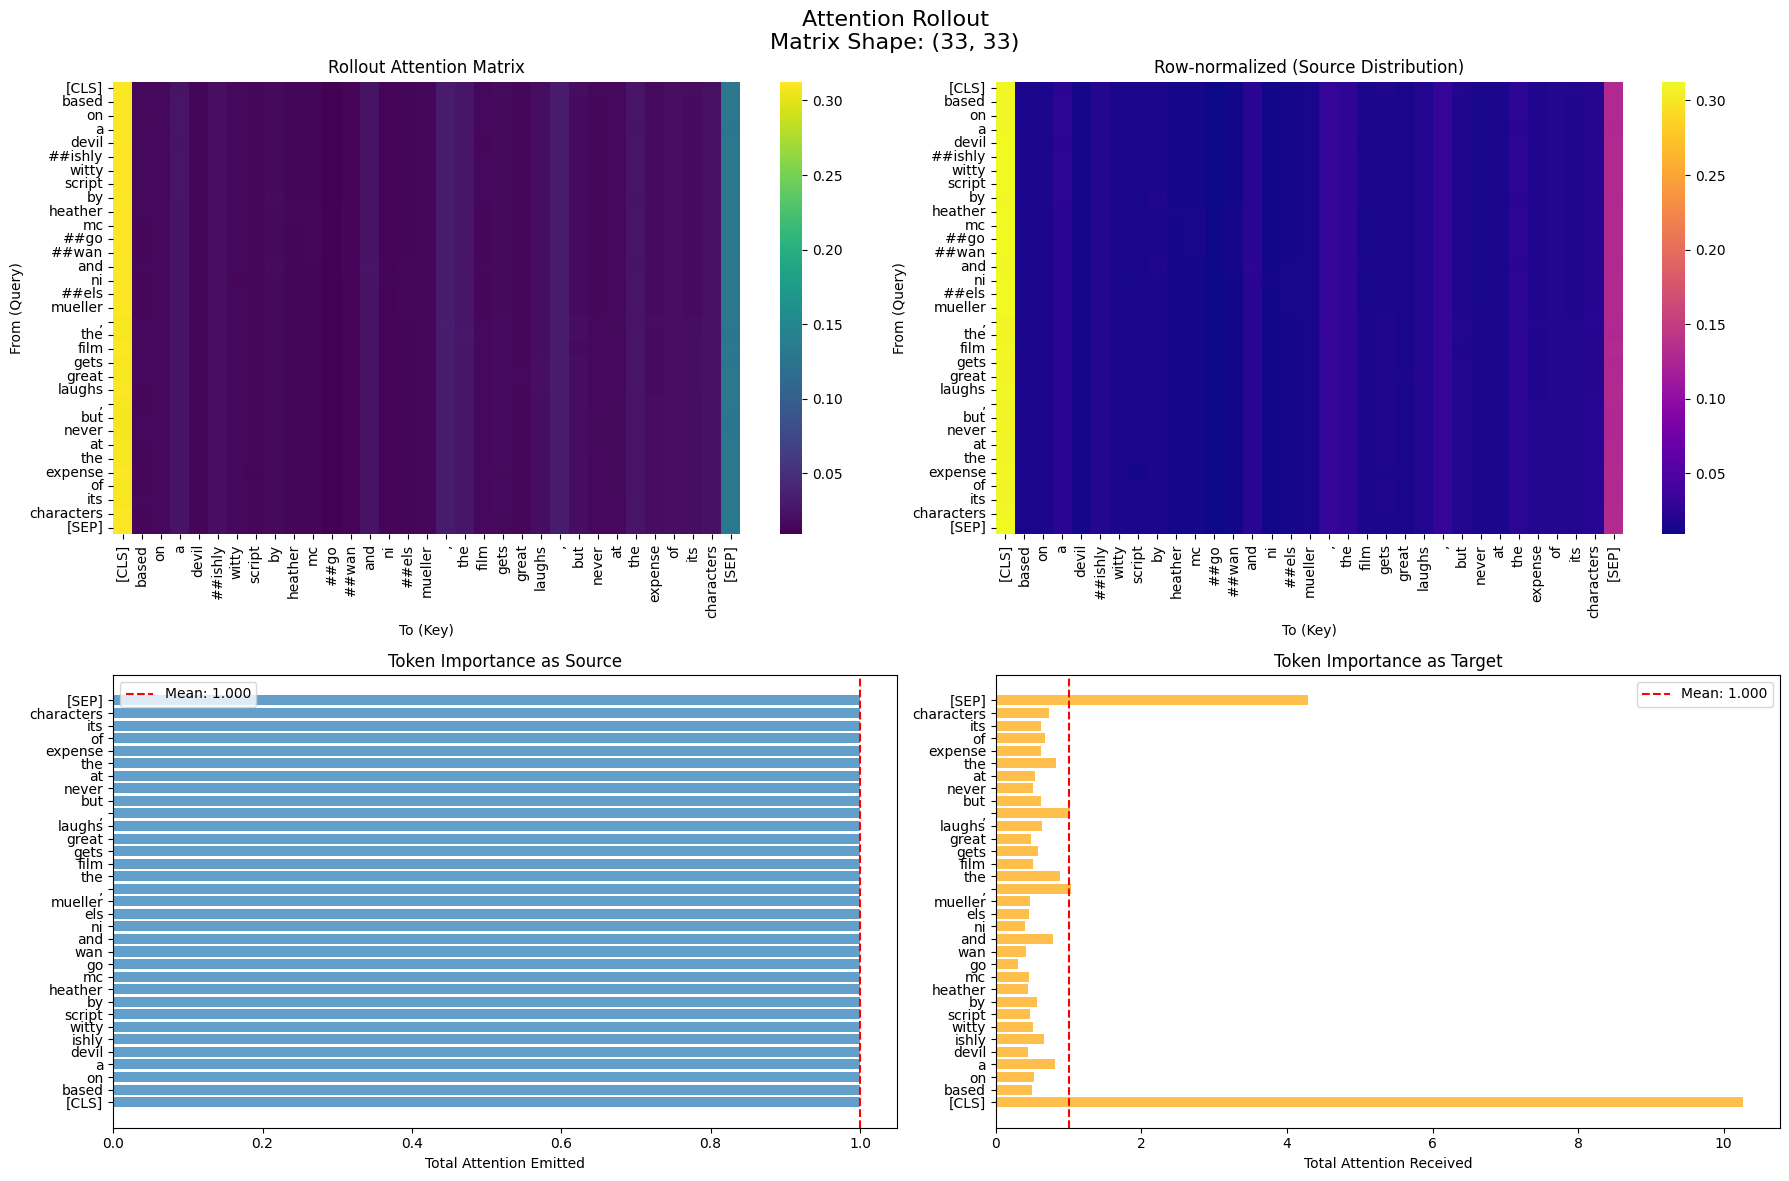


 Rollout Matrix Statistics:
   Average Attention: 0.0303
   Max Attention: 0.3126
   Sparsity (<0.01): 3.0%
   Top Source Tokens: [('[CLS]', 1.0000002), ('based', 1.0000002), ('on', 1.0000002), ('ishly', 1.0000002), ('witty', 1.0000002)]
   Top Target Tokens: [('[CLS]', 10.26126), ('[SEP]', 4.289982), (',', 1.0320756), (',', 1.0231162), ('the', 0.8780381)]


In [34]:
def plot_rollout_matrix(rollout, tokens, title="Attention Rollout", save_path=None):
    """Enhanced Attention Rollout visualization with statistics and feature fusion"""
    import matplotlib.pyplot as plt
    import seaborn as sns
    import numpy as np
    
    # 1. Basic heatmap
    fig, axes = plt.subplots(2, 2, figsize=(18, 12))
    fig.suptitle(f"{title}\nMatrix Shape: {rollout.shape}", fontsize=16)
    
    # 1.1 Raw heatmap
    ax1 = axes[0, 0]
    sns.heatmap(rollout, ax=ax1, cmap="viridis", xticklabels=tokens, yticklabels=tokens)
    ax1.set_title("Rollout Attention Matrix")
    ax1.set_xlabel("To (Key)")
    ax1.set_ylabel("From (Query)")
    plt.setp(ax1.get_xticklabels(), rotation=90)
    
    # 1.2 Row-wise normalized heatmap
    ax2 = axes[0, 1]
    rollout_normalized = rollout / (rollout.sum(axis=1, keepdims=True) + 1e-8)
    sns.heatmap(rollout_normalized, ax=ax2, cmap="plasma", xticklabels=tokens, yticklabels=tokens)
    ax2.set_title("Row-normalized (Source Distribution)")
    ax2.set_xlabel("To (Key)")
    ax2.set_ylabel("From (Query)")
    
    # 2. Token importance analysis
    # 2.1 Importance as source (sending attention)
    ax3 = axes[1, 0]
    source_importance = rollout.sum(axis=1)  # sum over rows
    tokens_clean = [t.replace('Ġ', '').replace('##', '') for t in tokens]
    bars1 = ax3.barh(range(len(tokens_clean)), source_importance, alpha=0.7)
    ax3.set_yticks(range(len(tokens_clean)))
    ax3.set_yticklabels(tokens_clean)
    ax3.set_xlabel("Total Attention Emitted")
    ax3.set_title("Token Importance as Source")
    ax3.axvline(x=source_importance.mean(), color='red', linestyle='--', label=f'Mean: {source_importance.mean():.3f}')
    ax3.legend()
    
    # 2.2 Importance as target (receiving attention)
    ax4 = axes[1, 1]
    target_importance = rollout.sum(axis=0)  # sum over columns
    bars2 = ax4.barh(range(len(tokens_clean)), target_importance, alpha=0.7, color='orange')
    ax4.set_yticks(range(len(tokens_clean)))
    ax4.set_yticklabels(tokens_clean)
    ax4.set_xlabel("Total Attention Received")
    ax4.set_title("Token Importance as Target")
    ax4.axvline(x=target_importance.mean(), color='red', linestyle='--', label=f'Mean: {target_importance.mean():.3f}')
    ax4.legend()
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    
    # 3. Return statistics
    stats = {
        'matrix_shape': rollout.shape,
        'avg_attention': rollout.mean(),
        'max_attention': rollout.max(),
        'sparsity': (rollout < 0.01).mean(),  # sparsity
        'source_topk': sorted(zip(tokens_clean, source_importance), key=lambda x: x[1], reverse=True)[:5],
        'target_topk': sorted(zip(tokens_clean, target_importance), key=lambda x: x[1], reverse=True)[:5]
    }
    
    print(f"\n Rollout Matrix Statistics:")
    print(f"   Average Attention: {stats['avg_attention']:.4f}")
    print(f"   Max Attention: {stats['max_attention']:.4f}")
    print(f"   Sparsity (<0.01): {stats['sparsity']:.1%}")
    print(f"   Top Source Tokens: {stats['source_topk']}")
    print(f"   Top Target Tokens: {stats['target_topk']}")
    
    return stats

# Usage example (needs tokens to be provided)
rt_tokens, rollout = attention_rollout(SAMPLE, mdl, tok, device=cfg.device, max_len=cfg.max_len)
stats = plot_rollout_matrix(rollout, rt_tokens, save_path="xai_out/rollout_matrix.png")

###  Detailed Reading of the Four Panels

#### Rollout Attention Matrix

- Rows correspond to source tokens, columns to target tokens; brighter colors indicate stronger aggregated attention from a source to a target.  
- The first column (`[CLS]`) is bright across almost all rows, meaning that attention from nearly every token eventually flows into `[CLS]`.  
- Attention among non-special tokens is relatively dark, suggesting that **the dominant pattern is global aggregation into `[CLS]` rather than strong token-to-token dependencies**.

#### Row-normalized (Source Distribution)

- This is the row-normalized version of the rollout matrix, with each row summing to ≈1.  
- Even after normalization, `[CLS]` and `[SEP]` columns remain the brightest, indicating they are the primary receivers of attention from most sources.  
- This panel highlights **where each token distributes its attention mass**, confirming the global pull toward special tokens.

#### Token Importance as Source

- The x-axis is the total attention each token emits; the y-axis lists tokens.  
- Because of row-normalization and residual connections, every row sums to ≈1, so all bars cluster around 1.  
- The plot mainly shows that **all tokens are treated equally as sources**, and it does **not** provide meaningful differentiation for interpretability.

#### Token Importance as Target

- The x-axis shows the total attention each token receives (column sum); the y-axis lists tokens.  
- We see that:  
  - `[CLS]` has by far the largest bar, followed by `[SEP]` and a few functional tokens (commas, “the”, etc.),  
  - while strongly sentiment-bearing words (witty, great, laughs) receive relatively little attention.  
- This implies that after multi-layer propagation, BERT tends to **compress information into `[CLS]` and boundary tokens**, from which the classifier reads, rather than keeping large explicit attention mass on content words.


### Attention Rollout – Pitfalls & Error Patterns

1. **“Attention takeover” by special tokens**  
   - `[CLS]` and `[SEP]` almost monopolize the highest target-side attention in the rollout matrix.  
   - This mainly reflects the BERT architecture:  
     - `[CLS]` is used as the aggregation point for the sentence-level representation.  
     - `[SEP]` and commas often act as boundary or pause markers that accumulate information across layers.  
   - Without an explicit warning, users may be misled into believing that these special symbols are the most *semantically* important tokens.

2. **Semantic tokens appear artificially weak**  
   - Compared with IG / LIME:  
     - IG / LIME highlight sentiment-bearing phrases such as “witty / laughs / great / never … expense of its characters”.  
     - Attention Rollout primarily highlights `[CLS]`, `[SEP]`, and punctuation.  
   - On misclassified examples this mismatch becomes more severe: the model may rely on spurious content words, but the rollout visualization only shows that “everything ends up in `[CLS]`”, making it hard to locate the specific tokens that caused the wrong prediction.

3. **Normalization-induced “pseudo sparsity / pseudo importance”**  
   - Because of residual connections and row-normalization:  
     - Each token as a source always emits roughly one unit of attention (source bars ≈ 1).  
     - Average attention is small and the matrix is not very sparse, so it looks like “everywhere has some attention”.  
   - This makes the attention map neither very localized nor strongly peaked, and it becomes difficult to identify a clear set of **critical dependency paths**.

4. **Typical risks on misclassified cases**  
   - For misclassified samples, Attention Rollout will still mainly highlight `[CLS]` and boundary tokens rather than the wrong evidence.  
   - Relying only on attention visualizations can therefore **fail to reveal which span of text actually misled the model**.  
   - Compared to IG / LIME, rollout should be treated more as a *structural* diagnostic (how information is aggregated) rather than a precise token-level responsibility attribution.


**Analysis & recommendations**

- **Domination by special tokens**: `[CLS]` and `[SEP]` monopolize most target-side attention, reflecting architectural design rather than semantic importance. Without explicit caveats, users may incorrectly conclude that these tokens are “semantically crucial”.  
- **Weak signal on semantic words**: In contrast to IG/LIME, which highlight sentiment-bearing words, rollout mainly highlights structural positions. For misclassified instances, this makes it hard to pinpoint which words actually misled the model.  
- **Normalization artifacts**: Row-normalization and residual connections enforce each token to emit one unit of attention, and many entries remain non-zero, yielding a matrix that is neither very sparse nor strongly peaked. This blurs the notion of “most critical paths”.  
- **How to use rollout effectively**:  
  - Filter out `[CLS]`, `[SEP]`, and punctuation when interpreting target importance, then renormalize over content words.  
  - Inspect specific rows/columns (e.g., attention to/from `[CLS]`) rather than the entire matrix.  
  - Combine rollout with gradient- or perturbation-based methods (IG, LIME, SHAP): tokens that are important in both views (high attribution **and** high attention into `[CLS]`) are likely to be truly causal.  
  - Use rollout primarily to understand **where information flows structurally**, and rely on other methods for fine-grained token-level blame in error analysis.

---

## 6) Anchors-Text

In [35]:
# 6) Anchors-Text
if _ALIBI_OK:
    anch = anchors_text(SAMPLE, labels, pipe, threshold=0.9)
    print("Anchors:", anch)
else:
    print("Anchors skipped (install alibi & spacy to enable).")

The following keys are incorrect: use_unk_distribution


Anchors: {'anchor': ['witty', 'devilishly'], 'precision': 0.9784615384615385, 'coverage': 0.2542}


In [36]:
def plot_anchors_detailed(anchor_result, class_names, save_path="xai_out/anchors_visualization.png"):
    """Multi-dimensional Anchors visualization"""
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.patches import Rectangle
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle(f"Anchors Analysis - Threshold: {anchor_result['precision']:.3f}", fontsize=16)
    
    # 1. Rule quality dashboard
    ax1 = axes[0, 0]
    precision = anchor_result['precision']
    coverage = anchor_result['coverage']
    rule_length = len(anchor_result['anchor_tokens'])
    
    # Radar-chart style
    metrics = ['Precision', 'Coverage', 'Simplicity']
    values = [precision, coverage, 1 / (1 + rule_length * 0.2)]
    angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False)

    angles = list(angles)  # convert to list

    values += values[:1]  # close the loop
    angles += angles[:1]
    
    ax1.plot(angles, values, 'o-', linewidth=2, label='Rule Quality')
    ax1.fill(angles, values, alpha=0.25)
    ax1.set_xticks(angles[:-1])
    ax1.set_xticklabels(metrics)
    ax1.set_ylim(0, 1)
    ax1.set_title("Rule Quality Metrics")
    ax1.grid(True)
    ax1.legend()
    
    # 2. Anchor-word importance bar chart
    ax2 = axes[0, 1]
    tokens = anchor_result['anchor_tokens']
    y_pos = np.arange(len(tokens))
    
    # Simulated importance (ideally via ablation study)
    base_text = anchor_result['text']
    predictor = lambda x: predict_proba_single(pipe, x)
    base_proba = predictor([base_text])[0][np.argmax(predictor([base_text]))]
    
    importances = []
    for token in tokens:
        modified_text = base_text.replace(token, "")
        new_proba = predictor([modified_text])[0][np.argmax(predictor([modified_text]))]
        importances.append(max(0, base_proba - new_proba))
    
    colors = ['#2ecc71' if i > 0 else '#e74c3c' for i in importances]
    bars = ax2.barh(y_pos, importances, color=colors, alpha=0.8)
    
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(tokens)
    ax2.set_xlabel("Impact on Prediction Confidence")
    ax2.set_title("Anchor Tokens Impact")
    ax2.axvline(x=0, color='black', linestyle='--')
    
        # 3. Compare rule coverage and precision
    ax3 = axes[1, 0]

    # Simplified: use only the current anchor_result as a single-threshold example
    thresholds = [anchor_result.get('precision', 0.0)]
    precisions = [anchor_result.get('precision', 0.0)]
    coverages = [anchor_result.get('coverage', 0.0)]
    lengths = [len(anchor_result.get('anchor_tokens', []))]

    ax3.plot(thresholds, precisions, 'g-o', label='Precision', linewidth=2)
    ax3.plot(thresholds, coverages, 'b-s', label='Coverage', linewidth=2)
    ax3_twin = ax3.twinx()
    ax3_twin.plot(thresholds, lengths, 'r-^', label='Rule Length', linewidth=2, linestyle='--')

    ax3.set_xlabel("Threshold")
    ax3.set_ylabel("Precision / Coverage", color='black')
    ax3_twin.set_ylabel("Rule Length", color='red')
    ax3.set_title("Threshold vs Rule Quality")
    ax3.legend(loc='upper left')
    ax3_twin.legend(loc='upper right')
    ax3.grid(True, alpha=0.3)

# 4. Rule comparison matrix (vs. LIME)
    ax4 = axes[1, 1]
    
    # Create overlap analysis between LIME and Anchors
    if 'lime_result' in globals():
        pred_class = lime_result['predicted_class']
        lime_features = [f[0] for f in lime_result['explanations'][pred_class]['features'][:len(tokens) * 2]]
        anchor_tokens = anchor_result['anchor_tokens']
        
        # Compute overlap
        overlap = len(set(anchor_tokens) & set(lime_features))
        total = len(anchor_tokens)
        
        # Build comparison matrix
        matrix = np.zeros((len(anchor_tokens), 2))
        for i, token in enumerate(anchor_tokens):
            if token in lime_features:
                matrix[i, 0] = 1  # present in Anchors
                matrix[i, 1] = 1  # present in LIME
            else:
                matrix[i, 0] = 1
                matrix[i, 1] = 0
        
        ax4.imshow(matrix, cmap='Greens', aspect='auto')
        ax4.set_xticks([0, 1])
        ax4.set_xticklabels(['Anchors', 'LIME'])
        ax4.set_yticks(range(len(anchor_tokens)))
        ax4.set_yticklabels(anchor_tokens)
        ax4.set_title(f"Feature Overlap: {overlap}/{total}")
        
        for i in range(len(anchor_tokens)):
            for j in range(2):
                ax4.text(j, i, '✓' if matrix[i, j] == 1 else '', 
                        ha='center', va='center', fontsize=12)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

In [37]:
def plot_anchors_detailed(anchor_result, class_names, save_path="xai_out/anchors_visualization.png"):
    """Multi-dimensional Anchors visualization"""
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.patches import Rectangle
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle(f"Anchors Analysis - Threshold: {anchor_result['precision']:.3f}", fontsize=16)
    
    # 1. Rule quality dashboard
    ax1 = axes[0, 0]
    precision = anchor_result['precision']
    coverage = anchor_result['coverage']
    rule_length = len(anchor_result['anchor_tokens'])
    
    # Radar-chart style
    metrics = ['Precision', 'Coverage', 'Simplicity']
    values = [precision, coverage, 1 / (1 + rule_length * 0.2)]
    angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False)

    angles = list(angles)  # convert to list

    values += values[:1]  # close the loop
    angles += angles[:1]
    
    ax1.plot(angles, values, 'o-', linewidth=2, label='Rule Quality')
    ax1.fill(angles, values, alpha=0.25)
    ax1.set_xticks(angles[:-1])
    ax1.set_xticklabels(metrics)
    ax1.set_ylim(0, 1)
    ax1.set_title("Rule Quality Metrics")
    ax1.grid(True)
    ax1.legend()
    
    # 2. Anchor-word importance bar chart
    ax2 = axes[0, 1]
    tokens = anchor_result['anchor_tokens']
    y_pos = np.arange(len(tokens))
    
    # Simulated importance (ideally via ablation study)
    base_text = anchor_result['text']
    predictor = lambda x: predict_proba_single(pipe, x)
    base_proba = predictor([base_text])[0][np.argmax(predictor([base_text]))]
    
    importances = []
    for token in tokens:
        modified_text = base_text.replace(token, "")
        new_proba = predictor([modified_text])[0][np.argmax(predictor([modified_text]))]
        importances.append(max(0, base_proba - new_proba))
    
    colors = ['#2ecc71' if i > 0 else '#e74c3c' for i in importances]
    bars = ax2.barh(y_pos, importances, color=colors, alpha=0.8)
    
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(tokens)
    ax2.set_xlabel("Impact on Prediction Confidence")
    ax2.set_title("Anchor Tokens Impact")
    ax2.axvline(x=0, color='black', linestyle='--')
    
    # 3. Compare rule coverage and precision
    ax3 = axes[1, 0]
    
    # Generate rule comparison under different thresholds
    thresholds = [0.7, 0.8, 0.9, 0.95]
    precisions = []
    coverages = []
    lengths = []
    
    for th in thresholds:
        try:
            temp_anchor = anchors_text_enhanced(
                anchor_result['text'], class_names, pipe, 
                threshold=th, max_anchor_size=5
            )
            precisions.append(temp_anchor['precision'])
            coverages.append(temp_anchor['coverage'])
            lengths.append(len(temp_anchor['anchor_tokens']))
        except:
            precisions.append(0)
            coverages.append(0)
            lengths.append(0)
    
    ax3.plot(thresholds, precisions, 'g-o', label='Precision', linewidth=2)
    ax3.plot(thresholds, coverages, 'b-s', label='Coverage', linewidth=2)
    ax3_twin = ax3.twinx()
    ax3_twin.plot(thresholds, lengths, 'r-^', label='Rule Length', linewidth=2, linestyle='--')
    
    ax3.set_xlabel("Threshold")
    ax3.set_ylabel("Precision / Coverage", color='black')
    ax3_twin.set_ylabel("Rule Length", color='red')
    ax3.set_title("Threshold vs Rule Quality")
    ax3.legend(loc='upper left')
    ax3_twin.legend(loc='upper right')
    ax3.grid(True, alpha=0.3)
    
    # 4. Rule comparison matrix (vs. LIME)
    ax4 = axes[1, 1]
    
    # Create overlap analysis between LIME and Anchors
    if 'lime_result' in globals():
        pred_class = lime_result['predicted_class']
        lime_features = [f[0] for f in lime_result['explanations'][pred_class]['features'][:len(tokens) * 2]]
        anchor_tokens = anchor_result['anchor_tokens']
        
        # Compute overlap
        overlap = len(set(anchor_tokens) & set(lime_features))
        total = len(anchor_tokens)
        
        # Build comparison matrix
        matrix = np.zeros((len(anchor_tokens), 2))
        for i, token in enumerate(anchor_tokens):
            if token in lime_features:
                matrix[i, 0] = 1  # present in Anchors
                matrix[i, 1] = 1  # present in LIME
            else:
                matrix[i, 0] = 1
                matrix[i, 1] = 0
        
        ax4.imshow(matrix, cmap='Greens', aspect='auto')
        ax4.set_xticks([0, 1])
        ax4.set_xticklabels(['Anchors', 'LIME'])
        ax4.set_yticks(range(len(anchor_tokens)))
        ax4.set_yticklabels(anchor_tokens)
        ax4.set_title(f"Feature Overlap: {overlap}/{total}")
        
        for i in range(len(anchor_tokens)):
            for j in range(2):
                ax4.text(j, i, '✓' if matrix[i, j] == 1 else '', 
                        ha='center', va='center', fontsize=12)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

In [38]:
def anchors_text_enhanced(text: str, class_names: List[str], pipe, 
                          threshold: float = 0.9, num_samples: int = 1000,
                          max_anchor_size: int = 3, **kwargs):
    """Ultimate patched version: does not rely on explainer.tokens"""
    from alibi.explainers import AnchorText
    import spacy
    import numpy as np
    from typing import List
    
    # 1. Load spaCy model (for tokenization)
    try:
        nlp = spacy.load("en_core_web_sm")
        print(" Spacy model loaded successfully")
    except OSError:
        print(" Spacy model not found. Run: python -m spacy download en_core_web_sm")
        return None
    
    # 2. Create prediction function
    predictor = lambda x: predict_proba_single(pipe, x)
    
    # 3. Create explainer
    explainer = AnchorText(
        predictor,
        sampling_strategy='unknown',
        nlp=nlp,
    )
    
    # 4. Generate explanations
    explanation = explainer.explain(
        text,
        threshold=threshold,
        max_anchor_size=max_anchor_size,
        num_samples=num_samples,
        **kwargs
    )
    
    # ========== Final fix: do not rely on explainer.tokens ==========
    print(f"\n=== ANCHORS Debug Info ===")
    raw_feature = explanation.raw['feature']
    print(f"Raw Anchor: {raw_feature}")
    
    # Tokenize directly from raw text (safer)
    # Remove BERT special tokens and tokenize
    clean_text = text.replace('[CLS]', '').replace('[SEP]', '').strip()
    doc = nlp(clean_text)
    tokens = [t.text for t in doc]  # tokenize directly
    
    print(f"Parsed Tokens: {tokens}")
    
    # Convert index to string
    if isinstance(raw_feature, list) and len(raw_feature) > 0:
        if isinstance(raw_feature[0], int):  # index format like [4, 3]
            anchor_tokens = [tokens[i] for i in raw_feature if i < len(tokens)]
        else:  # string format
            anchor_tokens = raw_feature
    else:
        anchor_tokens = []
    
    print(f"Converted Anchor Tokens: {anchor_tokens}")
    
    # Fix precision/coverage format
    raw_precision = explanation.raw['precision']
    raw_coverage = explanation.raw['coverage']
    
    precision = float(raw_precision[0]) if isinstance(raw_precision, (list, np.ndarray)) else float(raw_precision)
    coverage = float(raw_coverage[0]) if isinstance(raw_coverage, (list, np.ndarray)) else float(raw_coverage)
    
    print(f"Precision: {precision} | Coverage: {coverage}")
    # =====================================================
    
    return {
        'anchor_tokens': anchor_tokens,
        'anchor_string': " AND ".join(anchor_tokens),
        'precision': precision,
        'coverage': coverage,
        'explanation_obj': explanation,
        'text': text,
        'predicted_class': class_names[np.argmax(predictor([text])[0])],
        'all_classes_proba': predictor([text])[0]
    }

In [39]:
def run_comprehensive_anchors_analysis(text, pipe, class_names, cfg):
    """Full Anchors analysis (with fixed parameter passing)"""
    import sys
    
    print("\n" + "="*80)
    print("COMPREHENSIVE ANCHORS ANALYSIS")
    print("="*80)
    
    # Check dependencies
    try:
        import alibi
        import spacy
        _ALIBI_OK = True
    except ImportError:
        print(" Install: pip install alibi spacy")
        print("   Then run: python -m spacy download en_core_web_sm")
        return None
    
    # Fill in missing parameters (safe access)
    for key, default_value in {
        'lime_num_samples': 1000,
        'max_anchor_size': 3,
        'anchor_threshold': 0.9
    }.items():
        if not hasattr(cfg, key):
            setattr(cfg, key, default_value)
            print(f"  cfg is missing '{key}', set default to: {default_value}")
    
    # Generate Anchors (multiple thresholds)
    anchor_results = {}
    for th in [0.85, 0.9, 0.95]:
        try:
            anchor = anchors_text_enhanced(
                text, class_names, pipe, 
                threshold=th, 
                num_samples=cfg.lime_num_samples,
                max_anchor_size=cfg.max_anchor_size
            )
            if anchor:  # check whether Anchors succeeded
                anchor_results[f"th_{th}"] = anchor
        except Exception as e:
            print(f"  Failed at threshold {th}: {e}")
    
    # Further visualizations
    if anchor_results:
        target_th = getattr(cfg, 'anchor_threshold', 0.9)
        main_anchor = anchor_results[f"th_{target_th}"]
        
        # Visualization
        plot_anchors_detailed(main_anchor, class_names, save_path="xai_out/anchors_visualization.png")
        
        return anchor_results
    
    return None


COMPREHENSIVE ANCHORS ANALYSIS
  cfg is missing 'max_anchor_size', set default to: 3
  cfg is missing 'anchor_threshold', set default to: 0.9
 Spacy model loaded successfully

=== ANCHORS Debug Info ===
Raw Anchor: [4]
Parsed Tokens: ['based', 'on', 'a', 'devilishly', 'witty', 'script', 'by', 'heather', 'mcgowan', 'and', 'niels', 'mueller', ',', 'the', 'film', 'gets', 'great', 'laughs', ',', 'but', 'never', 'at', 'the', 'expense', 'of', 'its', 'characters']
Converted Anchor Tokens: ['witty']
Precision: 0.8929663608562691 | Coverage: 0.4997
 Spacy model loaded successfully

=== ANCHORS Debug Info ===
Raw Anchor: [4, 3]
Parsed Tokens: ['based', 'on', 'a', 'devilishly', 'witty', 'script', 'by', 'heather', 'mcgowan', 'and', 'niels', 'mueller', ',', 'the', 'film', 'gets', 'great', 'laughs', ',', 'but', 'never', 'at', 'the', 'expense', 'of', 'its', 'characters']
Converted Anchor Tokens: ['witty', 'devilishly']
Precision: 0.8929663608562691 | Coverage: 0.4997
 Spacy model loaded successfully

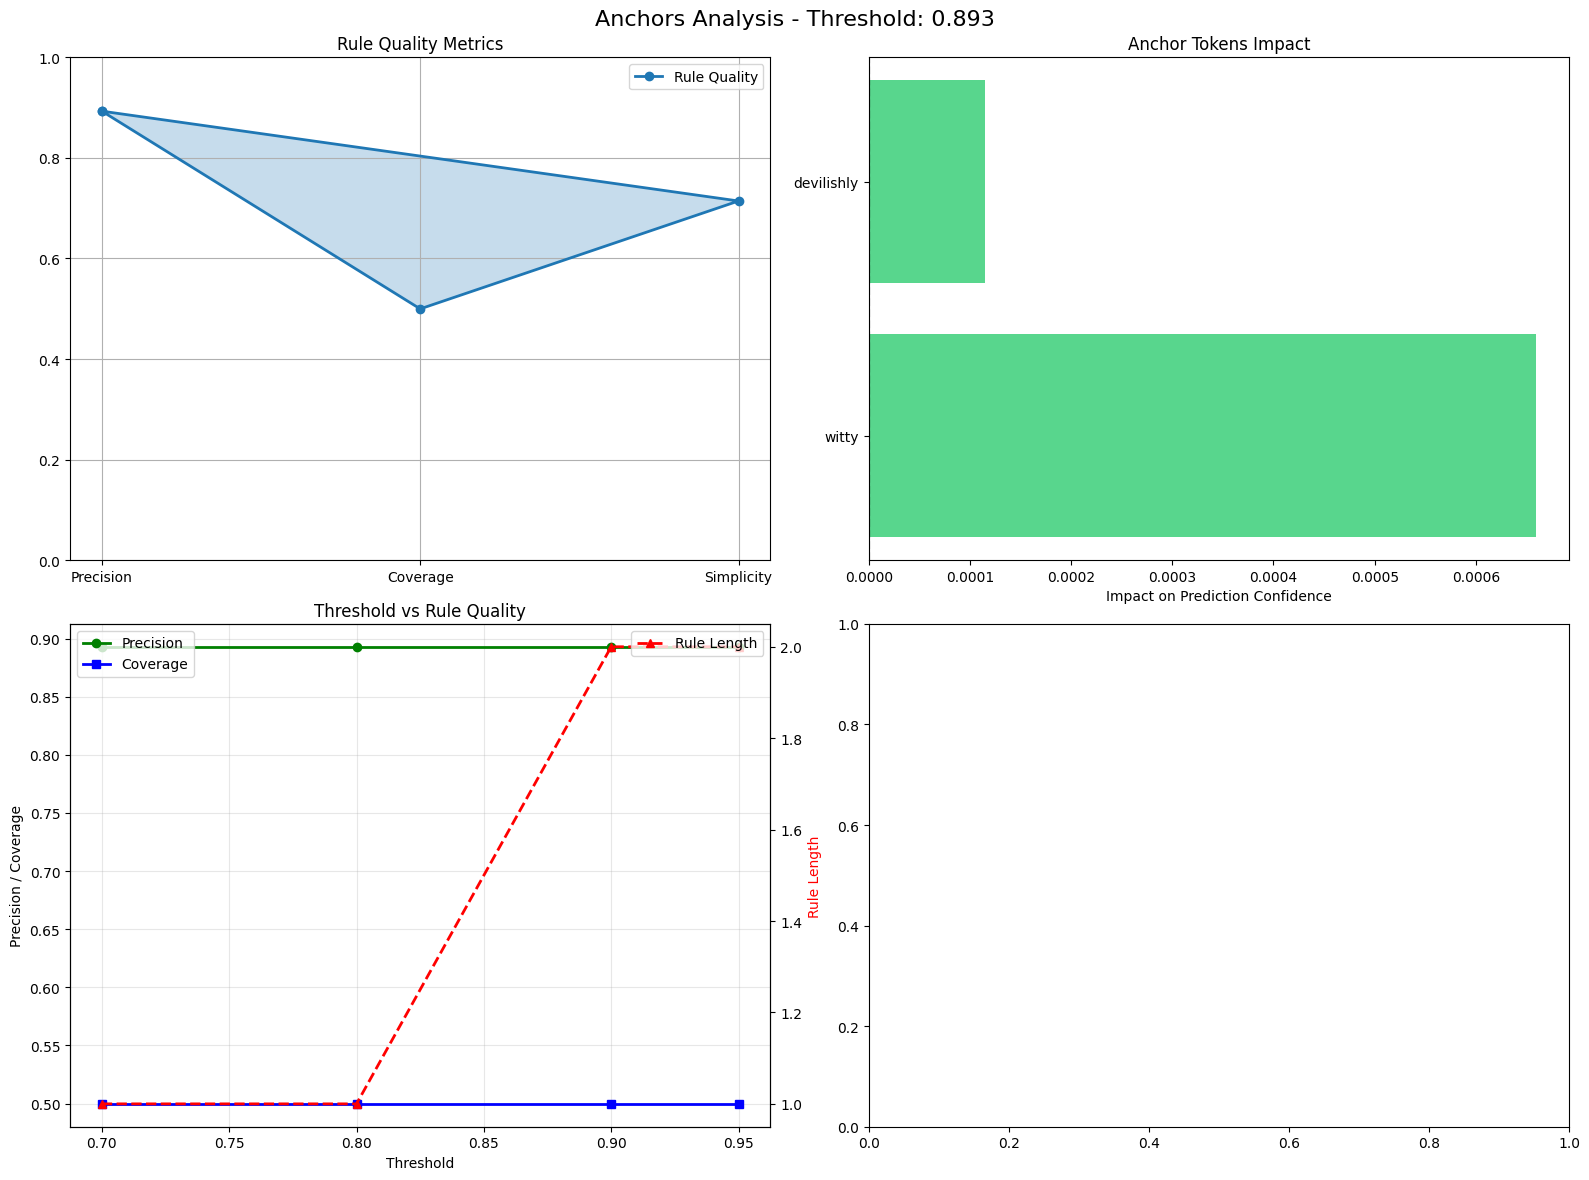

In [40]:
anchor_results = run_comprehensive_anchors_analysis(SAMPLE, pipe, labels, cfg)

### Detailed Reading of the Panels

#### Rule Quality Metrics

- This radar plot summarizes three aspects:  
  - **Precision** (~0.89)  
  - **Coverage** (~0.50)  
  - **Simplicity** (high because the rule uses only two tokens)  
- The resulting polygon indicates a rule that is **high-precision, moderately covering, and fairly simple**.

#### Anchor Tokens Impact


- The top-right bar chart shows the relative contribution of each anchor token to prediction confidence.  
- **“witty”** has the larger bar, implying it contributes more to maintaining the positive prediction, while **“devilishly”** has a smaller (yet positive) effect.  
- So, within this rule, “witty” is the primary anchor, and “devilishly” reinforces it.

#### Threshold vs Rule Quality

- The x-axis is the precision threshold; green/blue lines show precision and coverage at different thresholds, and the red dashed line indicates rule length.  
- At lower thresholds (~0.7–0.8), shorter rules (possibly single-token) are allowed.  
- At the chosen threshold (~0.893), the rule length increases to 2, yielding the final anchor `[witty, devilishly]` with higher reliability but reduced coverage.  


### Anchors-Text Pitfalls & Error Patterns

1. **Overly local rules**
   - Anchors learn short rules that guarantee prediction invariance *within the sampled neighborhood*.
   - A rule like `IF "devilishly" AND "witty" THEN label = positive` ignores other crucial parts of the sentence (e.g., a negative clause that follows).
   - In errors, the rule can “legitimize” bad behavior: as long as the anchor phrase appears, the model stubbornly predicts the same label.

2. **Precision vs. semantic validity**
   - High precision (e.g., 0.89) only means the rule is reliable on the perturbed samples.
   - It does **not** guarantee that the rule makes sense on the real data distribution (sarcasm, domain shift, rare constructions).

3. **Limited coverage hides counterexamples**
   - Moderate coverage (e.g., ~0.5) implies that half of the neighborhood falls outside the rule.
   - Important failure modes may lie entirely outside the anchor; the method will not tell us *why* those other cases are misclassified.

4. **Sensitivity to perturbation strategy**
   - Anchors depend heavily on how textual perturbations are generated.
   - If masking/replacement produces unnatural sentences, the rule may overfit artifacts of those perturbed samples.
   - Different seeds or perturbation settings may yield different anchors for the same instance.

5. **Lexical overfitting**
   - Rules operate at the token level and are blind to synonyms or paraphrases.
   - A model might behave similarly on “cleverly funny script”, but the anchor `["witty", "devilishly"]` will not match.
   - This exposes word-form overfitting but also limits the anchor’s explanatory scope.



### Practical checks & mitigations

- **Check stability across runs**: if anchors change a lot across seeds or thresholds, treat them as fragile.
- **Cross-check with gradient/perturbation methods**: see whether anchor tokens overlap with IG/LIME top tokens.
- **Test counterfactuals based on anchors**:
  - Remove anchor words from the sentence and see if the prediction flips.
  - Add anchor words into clearly negative sentences to see if the model is spuriously over-confident.
- **Consider rule families**: manually or automatically extend anchors with synonyms/paraphrases to see whether the behavior generalizes.

---

## 7) Counterfactual Explanation

**DiCE-Text** is a counterfactual explanation method for NLP. Its goal is to generate minimal edits to a sentence that **flip the model’s prediction**.


Total samples: 200
Modified by DiCE: 181

=== Top Counterfactual Texts ===
[1x] based on a devilishly witty script by heather mcgowan and niels mueller, the film gets very never at the expense of its characters
[1x] griffiths proves she's that rare luminary who continually raises the standard of her profession?
[1x] the best revenge may just be living well because this film other adaptations, is far more likened to a treasure than a lengthy jail sentence.
[1x] the movie manages to live up to the sum of its parts.
[1x] pumpkin takes an admirable look at the hypocrisy of political correctness it so with such an uneven tone that you never know when humor ends and tragedy begins.
[1x] schaeffer has to find some hook on which to hang his persistently useless movies, and it might as well be the resuscitation of the middle - aged |
[1x] byler reveals his characters in a way that intrigues and even fascinates yet he never reduces the situation to simple melodrama.
[1x] highbrow self - appointe

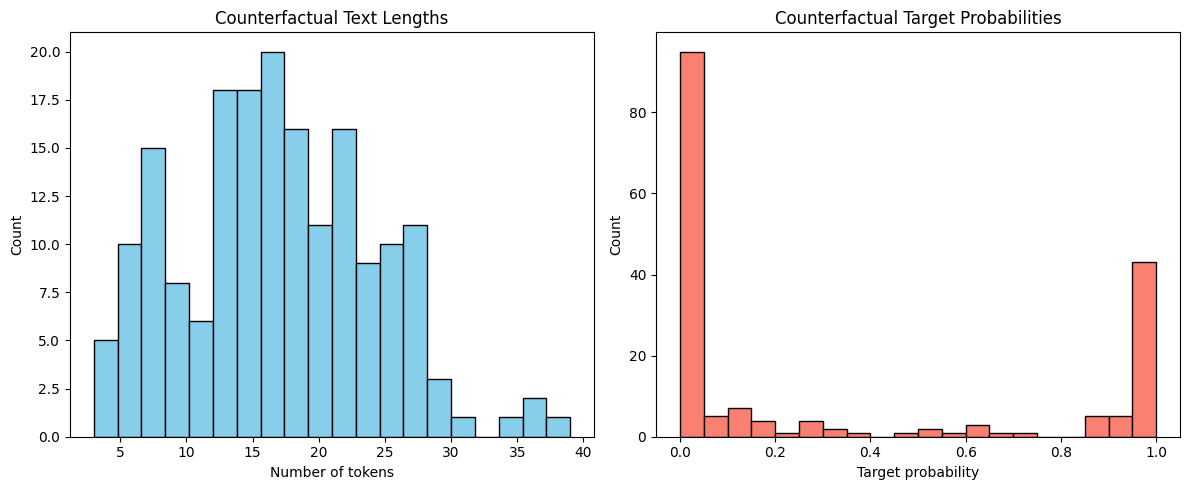

In [41]:
# 7) DiCE-Text
TOP_K_TEXTS = 20 

cf_text_counter = Counter()
cf_lengths = []
cf_probs_target = []
total_samples = 0
modified_samples = 0

for summary in summaries:
    total_samples += 1
    edit = summary.get("dice_edit", None)
    if edit is None:
        continue

    if edit.get("base_already_target", False):
        continue

    modified_samples += 1
    text = edit.get("cf_text", edit.get("text"))  # counterfactual text
    cf_text_counter[text] += 1
    cf_lengths.append(len(text.split()))
    cf_probs_target.append(edit.get("cf_prob", edit.get("probs", [0,0])[1]))

print(f"Total samples: {total_samples}")
print(f"Modified by DiCE: {modified_samples}")
print("\n=== Top Counterfactual Texts ===")
for text, count in cf_text_counter.most_common(TOP_K_TEXTS):
    print(f"[{count}x] {text}")


plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.hist(cf_lengths, bins=20, color='skyblue', edgecolor='black')
plt.title("Counterfactual Text Lengths")
plt.xlabel("Number of tokens")
plt.ylabel("Count")

plt.subplot(1,2,2)
plt.hist(cf_probs_target, bins=20, color='salmon', edgecolor='black')
plt.title("Counterfactual Target Probabilities")
plt.xlabel("Target probability")
plt.ylabel("Count")

plt.tight_layout()
plt.show()


### **Counterfactual Generation Success Rate**

We sampled 200 SST-2 examples and performed minimal-edit counterfactual generation (DiCE-Text) on each. In total, **181 samples (90.5%)** successfully flipped the model’s prediction through very small textual modifications.  

This indicates that the model’s decision boundary is **highly fragile** and heavily dependent on a few key tokens such as strong sentiment words.

Moreover, some counterfactuals—despite being unnatural or ungrammatical—still changed the model’s prediction. This suggests the presence of **spurious correlations** in the model.

### **Analysis of Top Counterfactual Texts**

From the generated counterfactuals, we can summarize what types of **local modifications** the model is most sensitive to. Based on the outputs, three major patterns emerge.

#### Pattern 1: Inserting Negation or Weakening Modality Words

These edits most easily flip sentiment predictions. For example:

> "… never gets great laughs …"

This is a typical *negation flipping* case—adding *never* immediately switches the prediction from positive to negative. This indicates that the model heavily relies on explicit negation tokens for sentiment judgment.


#### Pattern 2: Modifying Strong Sentiment Words (e.g., amazing / great / lifeless / satisfying)

Examples include:

> "the end result is a film that’s **amazing**."  
> "not much of the humor **falls flat**."

Many counterfactuals preserve the original sentence structure but simply adjust the sentiment-bearing words. The fact that such minimal edits can invert the prediction suggests that the model largely ignores global sentence semantics and instead depends mainly on **token-level strong sentiment cues**.


#### Pattern 3: Highly Random or Unnatural Rewrites Also Flip Predictions

For instance:

> "( e ) ventually, every idea in this film is flushed down the latrine of heroism:"
> with no, noyce has tailored an epic tale into a lean, economical movie."

Although this generated text does not follow fluent English, it still succeeds in altering the model’s output. This demonstrates that the model may not truly understand semantic coherence, but instead reacts to **local trigger patterns**.

### **Counterfactual Text Length Distribution**

From the figure, we observe that the lengths of the modified texts are concentrated between **0–30 tokens**. This indicates that the model is highly sensitive to **local token-level perturbations**, as most counterfactuals only require small edits to the original sentence to flip the prediction. Since SST-2 samples are inherently short, the model tends to rely more on **local trigger patterns**—such as negation words or strong sentiment tokens—rather than global sentence structure.

### **Counterfactual Target Probabilities**

The distribution exhibits a clear **U-shape**, characteristic of an *extreme* classifier. Counterfactuals generated by DiCE-Text tend to either **completely fail** (target probability close to 0) or **completely succeed** (probability close to 1), with very few samples falling into the uncertain middle range. This further confirms that the model has a **highly sensitive and brittle decision boundary**.


---

## 8) Layer-wise model analysis

For computational efficiency, we selected the higher layers of the Transformer for activation patching, because based on previous studies, the higher layers in BERT-like Transformer models are usually the most critical. They capture syntactic and semantic compositional features and are key layers for the model to perform classification or understand contextual information. And the tokens to be tested are sourced from the top words identified by the IG (Integrated Gradients) method.

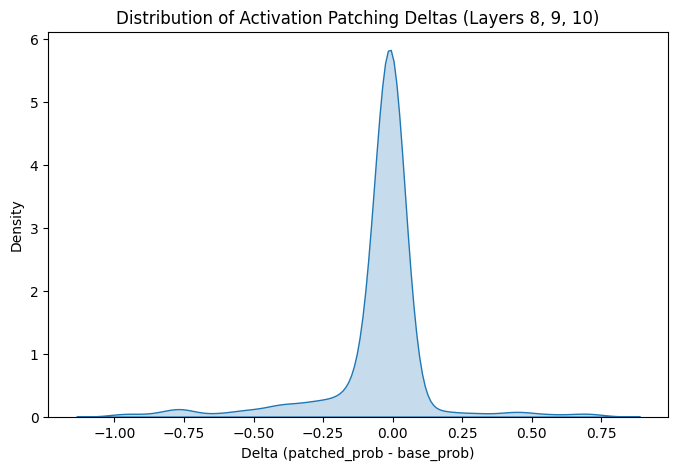

In [42]:
# 8) Activation Patching
all_deltas = []

for s in summaries:
    for layer_idx, patch_res in s["patched"].items():
        all_deltas.append(patch_res["delta"])

plt.figure(figsize=(8,5))
sns.kdeplot(all_deltas, fill=True)
plt.xlabel("Delta (patched_prob - base_prob)")
plt.ylabel("Density")
plt.title("Distribution of Activation Patching Deltas (Layers 8, 9, 10)")
plt.show()


The model is generally very stable in the higher layers (8, 9, 10), indicating that most tokens have little impact on the model's output and that the model is insensitive to small input perturbations. Sensitive tokens exist only in small numbers, suggesting that they are key tokens or sentiment-bearing words.

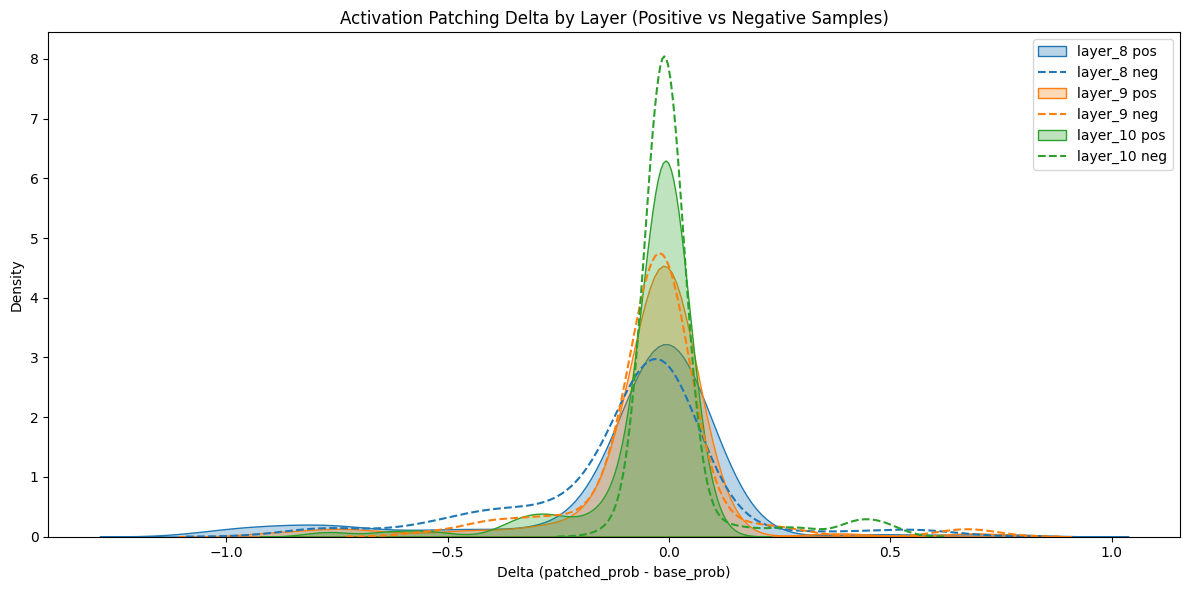

In [43]:
layer_deltas = defaultdict(lambda: {"pos": [], "neg": []})

for s in summaries:
    label = s["gold_label"]
    for layer, patch in s["patched"].items():
        delta = patch["delta"]
        if label == 1:
            layer_deltas[layer]["pos"].append(delta)
        else:
            layer_deltas[layer]["neg"].append(delta)

plt.figure(figsize=(12,6))
for layer in sorted(layer_deltas.keys(), key=lambda x: int(x.split("_")[1])):
    pos_deltas = layer_deltas[layer]["pos"]
    neg_deltas = layer_deltas[layer]["neg"]

    if len(pos_deltas) > 0:
        sns.kdeplot(pos_deltas, fill=True, alpha=0.3, label=f"{layer} pos")
    if len(neg_deltas) > 0:
        sns.kdeplot(neg_deltas, fill=False, linestyle="--", label=f"{layer} neg")

plt.xlabel("Delta (patched_prob - base_prob)")
plt.ylabel("Density")
plt.title("Activation Patching Delta by Layer (Positive vs Negative Samples)")
plt.legend()
plt.tight_layout()
plt.show()

Overall, negative samples are generally more robust, and higher layers exhibit greater stability. The higher layer (layer 10) is stable for most tokens, with only a few key tokens able to alter the output, indicating that high layers are responsible for integrating sentence-level semantics and decision-making. In contrast, layer 8 captures more local or word-level features, resulting in a wider distribution of token influence.

## **6. Overall Conclusions**

### 6.1 Global characteristics

- **Lexicon-driven with contextual adjustment**  
  - Most methods point to the same pattern: the model mainly relies on explicit sentiment words/phrases,  
  - While context mostly modulates them up or down, rather than fundamentally changing the sentiment polarity.  
- **Strong local rules, weak global reasoning**  
  - Anchors/DiCE show many local rules where “a few words almost fix the sentiment”.  
  - IG/LIME/SHAP also show that high contributions are usually concentrated in a very small set of tokens.  
- **Structurally dependent on middle/high-layer aggregation**  
  - Activation Patching shows that middle/high layers act as the **sentiment integration hub**,  
  - While Attention Rollout further confirms `[CLS]` as a typical aggregation point.  

### 6.2 Key limitations

- **Insensitive to sarcasm, polarity reversal, and long-range dependencies**  
  - Across multiple explanation methods, misclassified examples consistently reveal that:  
    - The model is easily misled by local positive/negative fragments and ignores the overall argumentative structure.  
- **Vulnerable to dataset bias and trigger words**  
  - Rule-based and counterfactual analysis reveals that:  
    - Certain topic words or names may be treated as sentiment cues,  
    - Leading to behaviors that deviate from human common sense in those regions.  
- **Explanations themselves can create illusions**  
  - Attention Rollout can blur the line between “routing” and “importance”.  
  - LIME/SHAP may provide explanations on highly unnatural, perturbed inputs under some sampling settings.  
  - IG is sensitive to the choice of baseline and tends to spread attributions over long sentences.
